In [1]:
from pathlib import Path
from typing import cast

import json

# pytorch
import torch
from torch import nn
from torch_geometric.data import Data

from dataset import add_stratified_masks, load_facebook_data
from modules import (
    MLPNetwork,
    MLPNetwork3Layer,
    MLPNetwork4Layer,
    MLPNetwork5Layer,
    MLPNetwork3LayerELU,
    MLPNetwork3LayerLReLU,
)

from train import (
    train_mlp_model,
    classification_metrics,
    plot_training_validation_loss,
    plot_training_validation_accuracy
)

# plotting
from matplotlib import pyplot as plt
import seaborn as sns

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### MLP Tuning
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Config and Constants

In [2]:
# constants
SEED = 808

# data parameters
TRAIN_PCT = 60
VAL_PCT = 20
TEST_PCT = 20

# MLP model parameters
HIDDEN_CHANNELS = 64
HIDDEN_CHANNELS_32 = 32
HIDDEN_CHANNELS_128 = 128
DROPOUT = 0.5
DROPOUT_03 = 0.3
DROPOUT_055 = 0.55
DROPOUT_06 = 0.6
DROPOUT_07 = 0.7

# loss function
CRITERION = nn.CrossEntropyLoss()

# hyper-parameters
LEARNING_RATE = 1e-3
LEARNING_RATE_5E4 = 5e-4
LEARNING_RATE_2E3 = 2e-3
LEARNING_RATE_1E4 = 1e-4
WEIGHT_DECAY = 0.0
WEIGHT_DECAY_5E5 = 5e-5
WEIGHT_DECAY_1E4 = 1e-4
WEIGHT_DECAY_5E4 = 5e-4
WEIGHT_DECAY_1E3 = 1e-3

EPOCHS_4K = 4000
EPOCHS_2K = 2000

# plot styling
sns.set_theme(
    context="notebook",
    style="whitegrid",
)

# output paths
RESULTS_DIR = Path("results")
CHECKPOINTS_DIR = Path("checkpoints")
FIGURES_DIR = Path("images/mlp")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Television show",
    "Government",
    "Company",
    "Politician",
]

In [3]:
# Device configuration
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce GTX 950M


Load the Facebook Graph

In [4]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()
data = dataset[0]  # get first graph object

# create reproducible stratified train/validation/test splits
add_stratified_masks(
    cast(Data, data),
    train_pct=TRAIN_PCT,
    val_pct=VAL_PCT,
    test_pct=TEST_PCT,
    seed=SEED,
)

# load data onto the device
data = data.to(device)

### Depth Tuning

Ensure the Torch seed rng is reset

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 2-Layer MLP network

In [6]:
mlp2_model = MLPNetwork(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 2-Layer MLP

In [7]:
# optimiser
mlp2_optimizer = torch.optim.Adam(
    mlp2_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 2-Layer MLP Candidate

In [8]:
# perform training and validation of the 2-Layer MLP

mlp2_result = train_mlp_model(
    model=mlp2_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp2_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training MLP
Epoch [   1/4000] Train Loss: 1.39133 | Val Loss: 1.38521 | Val Acc: 30.82%
Epoch [ 100/4000] Train Loss: 0.85057 | Val Loss: 0.82983 | Val Acc: 70.34%
Epoch [ 200/4000] Train Loss: 0.66170 | Val Loss: 0.64504 | Val Acc: 74.25%
Epoch [ 300/4000] Train Loss: 0.61287 | Val Loss: 0.60630 | Val Acc: 75.57%
Epoch [ 400/4000] Train Loss: 0.58360 | Val Loss: 0.59015 | Val Acc: 76.50%
Epoch [ 500/4000] Train Loss: 0.56785 | Val Loss: 0.58010 | Val Acc: 76.88%
Epoch [ 600/4000] Train Loss: 0.55026 | Val Loss: 0.57329 | Val Acc: 77.35%
Epoch [ 700/4000] Train Loss: 0.53877 | Val Loss: 0.56772 | Val Acc: 77.81%
Epoch [ 800/4000] Train Loss: 0.52696 | Val Loss: 0.56405 | Val Acc: 77.99%
Epoch [ 900/4000] Train Loss: 0.51712 | Val Loss: 0.56094 | Val Acc: 78.30%
Epoch [1000/4000] Train Loss: 0.51087 | Val Loss: 0.55860 | Val Acc: 78.48%
Epoch [1100/4000] Train Loss: 0.50401 | Val Loss: 0.55636 | Val Acc: 78.86%
Epoch [1200/4000] Train Loss: 0.49976 | Val Loss: 0.55486 | Val Acc: 79.0

Restore best result for 2-Layer MLP evaluation

In [9]:
# check that a best state exists
if mlp2_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp2_model.load_state_dict(
    mlp2_result["best_state"]
)

mlp2_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp2_logits = mlp2_model(
        data.x,
    )

# calculate validation metrics
mlp2_metrics = classification_metrics(
    logits=mlp2_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 2-Layer MLP evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp2_result['best_epoch']}\n"
    f"Validation loss: {mlp2_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp2_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp2_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp2_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp2_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp2_metrics['macro_auroc']:.4f}"
)

Best epoch:      1545
Validation loss: 0.55159
Accuracy:        0.7973
Macro precision: 0.7915
Macro recall:    0.7727
Macro F1:        0.7796
Macro AUROC:     0.9467


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp2_metrics['precision'][i]:.4f}  "
        f"R={mlp2_metrics['recall'][i]:.4f}  "
        f"F1={mlp2_metrics['f1'][i]:.4f}  "
        f"n={mlp2_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8182  R=0.8383  F1=0.8281  n=1299
Government       P=0.7913  R=0.8488  F1=0.8191  n=1376
Company          P=0.7990  R=0.8031  F1=0.8010  n=1153
Politician       P=0.7576  R=0.6006  F1=0.6700  n=666


Visualise Validation Loss for the 2-Layer MLP

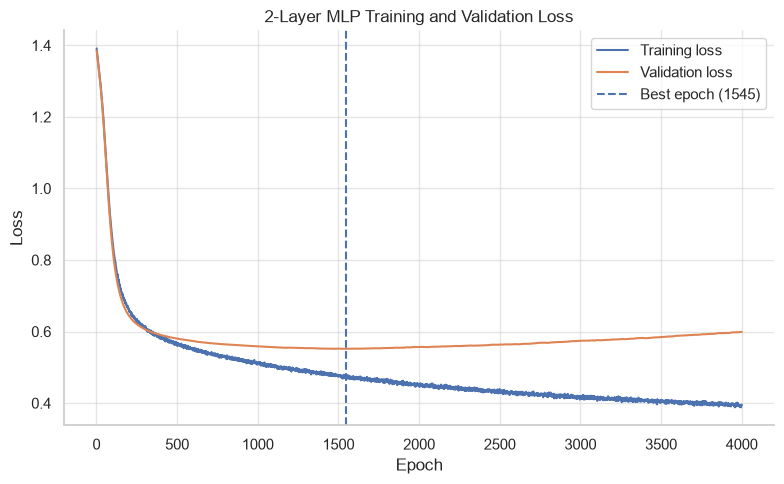

In [12]:
mlp2_loss_fig, _ = plot_training_validation_loss(
    history=mlp2_result["history"],
    best_epoch=mlp2_result["best_epoch"],
    title="2-Layer MLP Training and Validation Loss",
)

plt.show()

In [13]:
mlp2_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_2layer_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 2-Layer MLP

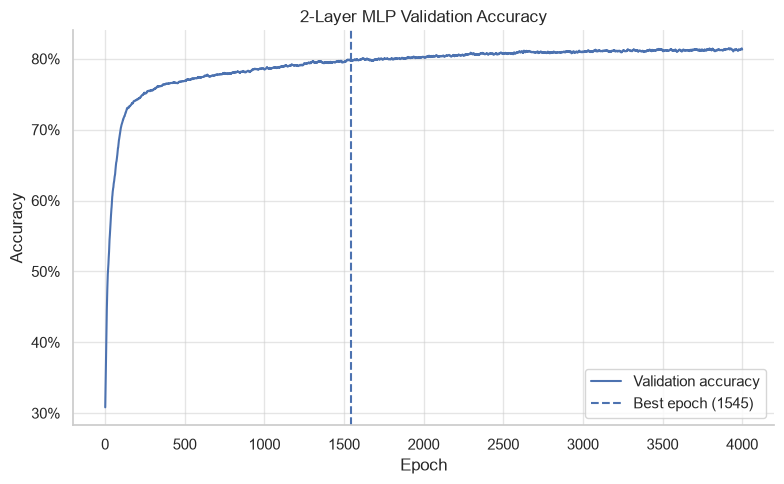

In [14]:
mlp2_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp2_result["history"],
    best_epoch=mlp2_result["best_epoch"],
    title="2-Layer MLP Validation Accuracy",
)

plt.show()

In [15]:
mlp2_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_2layer_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 2-Layer MLP Candidate Results

In [16]:
# save 2-Layer MLP experiment results
mlp2_results = {
    "model": "MLP",
    "experiment": "depth",
    "num_layers": 2,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp2_result["best_epoch"],
    "best_val_loss": mlp2_result["best_val_loss"],
    "training_seconds": mlp2_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp2_metrics,
    "history": mlp2_result["history"],
}

with (
    RESULTS_DIR / "mlp_depth_2layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp2_results,
        file,
        indent=2,
    )

torch.save(
    mlp2_result["best_state"],
    CHECKPOINTS_DIR / "mlp_depth_2layer.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 3-Layer MLP network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP

In [7]:
# optimiser
mlp3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 3-Layer MLP Candidate

In [8]:
# perform training and validation of the 3-Layer MLP

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training MLP
Epoch [   1/4000] Train Loss: 1.40239 | Val Loss: 1.39798 | Val Acc: 26.39%
Epoch [ 100/4000] Train Loss: 0.72987 | Val Loss: 0.67394 | Val Acc: 73.25%
Epoch [ 200/4000] Train Loss: 0.59033 | Val Loss: 0.58267 | Val Acc: 77.48%
Epoch [ 300/4000] Train Loss: 0.54961 | Val Loss: 0.56120 | Val Acc: 78.70%
Epoch [ 400/4000] Train Loss: 0.51344 | Val Loss: 0.55021 | Val Acc: 79.93%
Epoch [ 500/4000] Train Loss: 0.49554 | Val Loss: 0.54175 | Val Acc: 80.89%
Epoch [ 600/4000] Train Loss: 0.47859 | Val Loss: 0.53755 | Val Acc: 81.17%
Epoch [ 700/4000] Train Loss: 0.46292 | Val Loss: 0.53333 | Val Acc: 81.44%
Epoch [ 800/4000] Train Loss: 0.45223 | Val Loss: 0.53162 | Val Acc: 81.80%
Epoch [ 900/4000] Train Loss: 0.43459 | Val Loss: 0.53313 | Val Acc: 81.53%
Epoch [1000/4000] Train Loss: 0.42785 | Val Loss: 0.53249 | Val Acc: 82.04%
Epoch [1100/4000] Train Loss: 0.42751 | Val Loss: 0.53306 | Val Acc: 81.89%
Epoch [1200/4000] Train Loss: 0.41290 | Val Loss: 0.53459 | Val Acc: 82.0

Restore best result for 3-Layer MLP evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1010
Validation loss: 0.53122
Accuracy:        0.8184
Macro precision: 0.8081
Macro recall:    0.7969
Macro F1:        0.8013
Macro AUROC:     0.9512


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8297  R=0.8437  F1=0.8366  n=1299
Government       P=0.8355  R=0.8561  F1=0.8457  n=1376
Company          P=0.8198  R=0.8482  F1=0.8338  n=1153
Politician       P=0.7474  R=0.6396  F1=0.6893  n=666


Visualise Validation Loss for the 3-Layer MLP

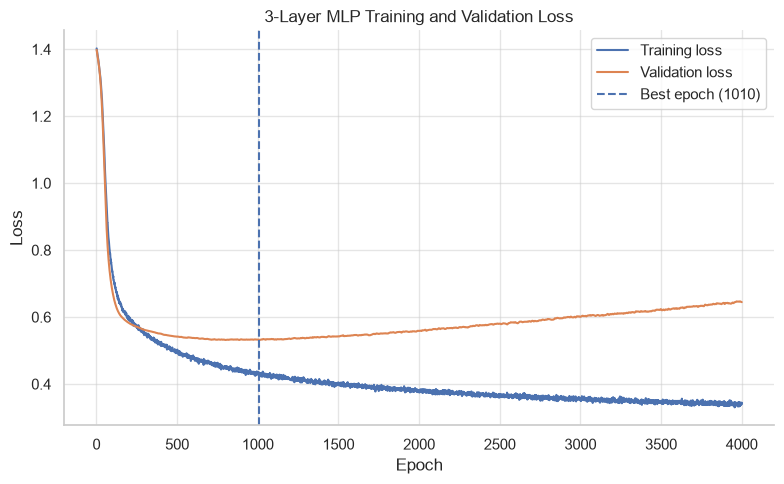

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_3layer_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP

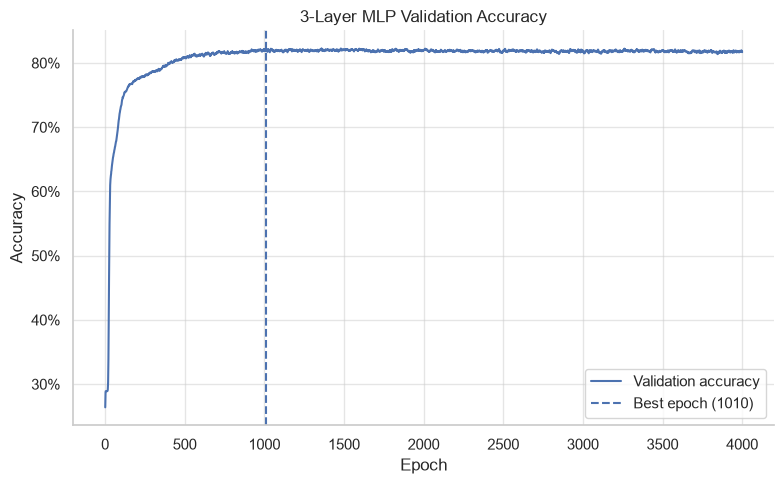

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_3layer_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP Candidate Results

In [16]:
# save 3-Layer MLP experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "depth",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_depth_3layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_depth_3layer.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 4-Layer MLP network

In [6]:
mlp4_model = MLPNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 4-Layer MLP

In [7]:
# optimiser
mlp4_optimizer = torch.optim.Adam(
    mlp4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer MLP Candidate

In [8]:
# perform training and validation of the 4-Layer MLP

mlp4_result = train_mlp_model(
    model=mlp4_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40729 | Val Loss: 1.40344 | Val Acc: 14.82%
Epoch [ 100/2000] Train Loss: 0.72660 | Val Loss: 0.65727 | Val Acc: 74.86%
Epoch [ 200/2000] Train Loss: 0.56833 | Val Loss: 0.56829 | Val Acc: 78.46%
Epoch [ 300/2000] Train Loss: 0.51134 | Val Loss: 0.54255 | Val Acc: 80.84%
Epoch [ 400/2000] Train Loss: 0.47865 | Val Loss: 0.53377 | Val Acc: 81.33%
Epoch [ 500/2000] Train Loss: 0.45750 | Val Loss: 0.53403 | Val Acc: 81.75%
Epoch [ 600/2000] Train Loss: 0.44123 | Val Loss: 0.53392 | Val Acc: 81.89%
Epoch [ 700/2000] Train Loss: 0.43111 | Val Loss: 0.53393 | Val Acc: 81.93%
Epoch [ 800/2000] Train Loss: 0.41388 | Val Loss: 0.53516 | Val Acc: 81.80%
Epoch [ 900/2000] Train Loss: 0.41138 | Val Loss: 0.54085 | Val Acc: 81.98%
Epoch [1000/2000] Train Loss: 0.40182 | Val Loss: 0.54492 | Val Acc: 82.24%
Epoch [1100/2000] Train Loss: 0.39839 | Val Loss: 0.54656 | Val Acc: 82.13%
Epoch [1200/2000] Train Loss: 0.39337 | Val Loss: 0.55191 | Val Acc: 82.2

Restore best result for 4-Layer MLP evaluation

In [9]:
# check that a best state exists
if mlp4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp4_model.load_state_dict(
    mlp4_result["best_state"]
)

mlp4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp4_logits = mlp4_model(
        data.x,
    )

# calculate validation metrics
mlp4_metrics = classification_metrics(
    logits=mlp4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer MLP evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp4_result['best_epoch']}\n"
    f"Validation loss: {mlp4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp4_metrics['macro_auroc']:.4f}"
)

Best epoch:      658
Validation loss: 0.53141
Accuracy:        0.8175
Macro precision: 0.8062
Macro recall:    0.7953
Macro F1:        0.7997
Macro AUROC:     0.9512


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp4_metrics['precision'][i]:.4f}  "
        f"R={mlp4_metrics['recall'][i]:.4f}  "
        f"F1={mlp4_metrics['f1'][i]:.4f}  "
        f"n={mlp4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8225  R=0.8560  F1=0.8389  n=1299
Government       P=0.8343  R=0.8561  F1=0.8451  n=1376
Company          P=0.8319  R=0.8326  F1=0.8322  n=1153
Politician       P=0.7361  R=0.6366  F1=0.6828  n=666


Visualise Validation Loss for the 4-Layer MLP

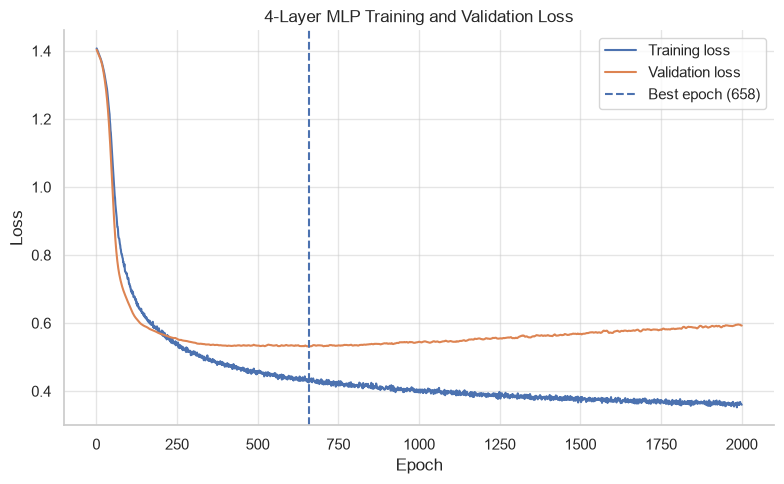

In [12]:
mlp4_loss_fig, _ = plot_training_validation_loss(
    history=mlp4_result["history"],
    best_epoch=mlp4_result["best_epoch"],
    title="4-Layer MLP Training and Validation Loss",
)

plt.show()

In [13]:
mlp4_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_4layer_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer MLP

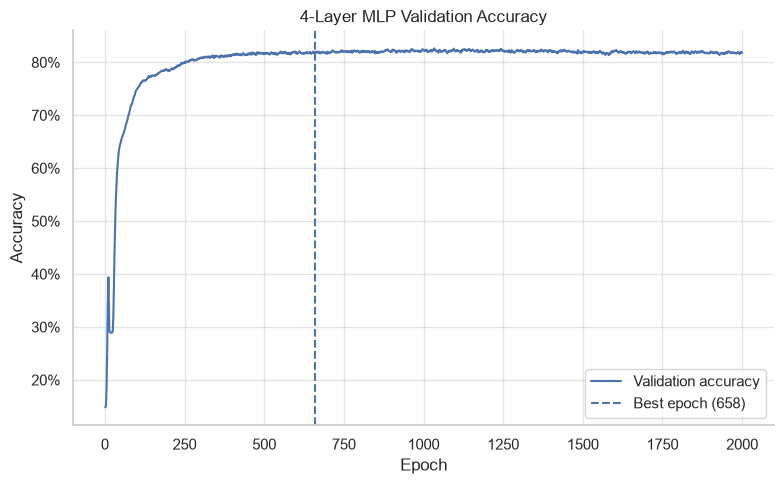

In [14]:
mlp4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp4_result["history"],
    best_epoch=mlp4_result["best_epoch"],
    title="4-Layer MLP Validation Accuracy",
)

plt.show()

In [15]:
mlp4_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_4layer_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer MLP Candidate Results

In [16]:
# save 4-Layer MLP experiment results
mlp4_results = {
    "model": "MLP",
    "experiment": "depth",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp4_result["best_epoch"],
    "best_val_loss": mlp4_result["best_val_loss"],
    "training_seconds": mlp4_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp4_metrics,
    "history": mlp4_result["history"],
}

with (
    RESULTS_DIR / "mlp_depth_4layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp4_results,
        file,
        indent=2,
    )

torch.save(
    mlp4_result["best_state"],
    CHECKPOINTS_DIR / "mlp_depth_4layer.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 5-Layer MLP network

In [6]:
mlp5_model = MLPNetwork5Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 5-Layer MLP

In [7]:
# optimiser
mlp5_optimizer = torch.optim.Adam(
    mlp5_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 5-Layer MLP Candidate

In [8]:
# perform training and validation of the 5-Layer MLP

mlp5_result = train_mlp_model(
    model=mlp5_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp5_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.38503 | Val Loss: 1.38184 | Val Acc: 30.62%
Epoch [ 100/2000] Train Loss: 0.71656 | Val Loss: 0.65272 | Val Acc: 75.03%
Epoch [ 200/2000] Train Loss: 0.56243 | Val Loss: 0.56257 | Val Acc: 79.62%
Epoch [ 300/2000] Train Loss: 0.50435 | Val Loss: 0.55098 | Val Acc: 81.04%
Epoch [ 400/2000] Train Loss: 0.47106 | Val Loss: 0.55041 | Val Acc: 81.29%
Epoch [ 500/2000] Train Loss: 0.43880 | Val Loss: 0.55632 | Val Acc: 81.42%
Epoch [ 600/2000] Train Loss: 0.42904 | Val Loss: 0.56755 | Val Acc: 81.31%
Epoch [ 700/2000] Train Loss: 0.41816 | Val Loss: 0.57093 | Val Acc: 81.55%
Epoch [ 800/2000] Train Loss: 0.41785 | Val Loss: 0.57393 | Val Acc: 81.35%
Epoch [ 900/2000] Train Loss: 0.40050 | Val Loss: 0.58759 | Val Acc: 81.31%
Epoch [1000/2000] Train Loss: 0.39913 | Val Loss: 0.59676 | Val Acc: 80.82%
Epoch [1100/2000] Train Loss: 0.38753 | Val Loss: 0.60050 | Val Acc: 81.33%
Epoch [1200/2000] Train Loss: 0.38773 | Val Loss: 0.61017 | Val Acc: 80.9

Restore best result for 5-Layer MLP evaluation

In [9]:
# check that a best state exists
if mlp5_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp5_model.load_state_dict(
    mlp5_result["best_state"]
)

mlp5_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp5_logits = mlp5_model(
        data.x,
    )

# calculate validation metrics
mlp5_metrics = classification_metrics(
    logits=mlp5_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 5-Layer MLP evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp5_result['best_epoch']}\n"
    f"Validation loss: {mlp5_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp5_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp5_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp5_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp5_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp5_metrics['macro_auroc']:.4f}"
)

Best epoch:      431
Validation loss: 0.54747
Accuracy:        0.8180
Macro precision: 0.8078
Macro recall:    0.7952
Macro F1:        0.8001
Macro AUROC:     0.9475


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp5_metrics['precision'][i]:.4f}  "
        f"R={mlp5_metrics['recall'][i]:.4f}  "
        f"F1={mlp5_metrics['f1'][i]:.4f}  "
        f"n={mlp5_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8170  R=0.8591  F1=0.8375  n=1299
Government       P=0.8386  R=0.8532  F1=0.8458  n=1376
Company          P=0.8285  R=0.8378  F1=0.8331  n=1153
Politician       P=0.7473  R=0.6306  F1=0.6840  n=666


Visualise Validation Loss for the 5-Layer MLP

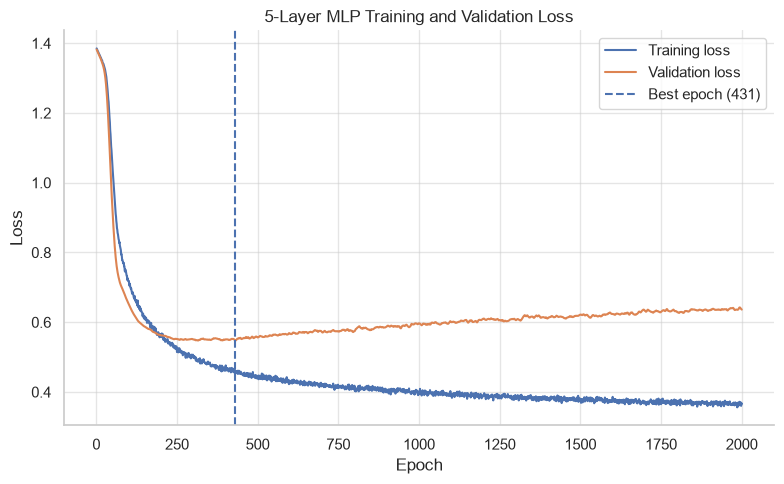

In [12]:
mlp5_loss_fig, _ = plot_training_validation_loss(
    history=mlp5_result["history"],
    best_epoch=mlp5_result["best_epoch"],
    title="5-Layer MLP Training and Validation Loss",
)

plt.show()

In [13]:
mlp5_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_5layer_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 5-Layer MLP

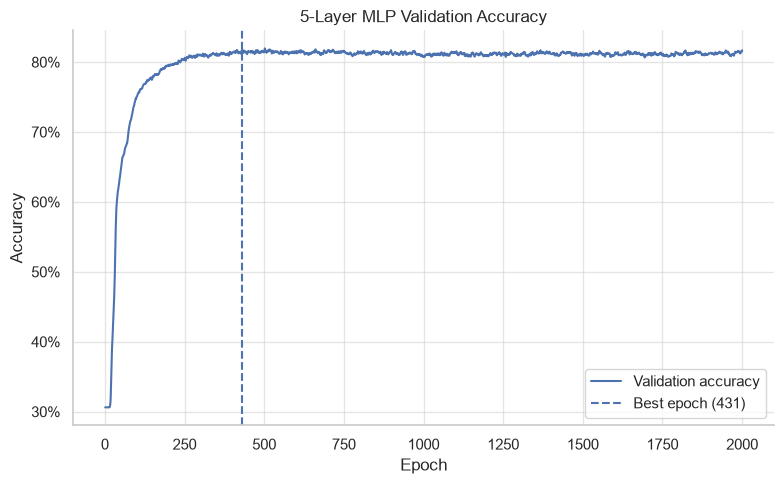

In [14]:
mlp5_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp5_result["history"],
    best_epoch=mlp5_result["best_epoch"],
    title="5-Layer MLP Validation Accuracy",
)

plt.show()

In [15]:
mlp5_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_depth_5layer_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 5-Layer MLP Candidate Results

In [16]:
# save 5-Layer MLP experiment results
mlp5_results = {
    "model": "MLP",
    "experiment": "depth",
    "num_layers": 5,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp5_result["best_epoch"],
    "best_val_loss": mlp5_result["best_val_loss"],
    "training_seconds": mlp5_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp5_metrics,
    "history": mlp5_result["history"],
}

with (
    RESULTS_DIR / "mlp_depth_5layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp5_results,
        file,
        indent=2,
    )

torch.save(
    mlp5_result["best_state"],
    CHECKPOINTS_DIR / "mlp_depth_5layer.pt",
)

The 3-layer MLP performed best on every aggregate validation measure.<br>
Three layers is either best or essentially tied on every per-class F1.<br>
The 3-layer MLP provides the best recall for the difficult Politician class.<br>
Therefore, three layers was selected for subsequent training.

### Dropout Tuning

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (dropout=0.3) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_03,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (dropout=0.3)

In [7]:
# optimiser
mlp3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 3-Layer MLP (dropout=0.3) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (dropout=0.3)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40125 | Val Loss: 1.39792 | Val Acc: 26.50%
Epoch [ 100/2000] Train Loss: 0.66639 | Val Loss: 0.64732 | Val Acc: 74.43%
Epoch [ 200/2000] Train Loss: 0.54806 | Val Loss: 0.57654 | Val Acc: 77.39%
Epoch [ 300/2000] Train Loss: 0.50301 | Val Loss: 0.55814 | Val Acc: 79.06%
Epoch [ 400/2000] Train Loss: 0.46435 | Val Loss: 0.55340 | Val Acc: 80.26%
Epoch [ 500/2000] Train Loss: 0.44012 | Val Loss: 0.55687 | Val Acc: 80.60%
Epoch [ 600/2000] Train Loss: 0.41427 | Val Loss: 0.56293 | Val Acc: 81.09%
Epoch [ 700/2000] Train Loss: 0.39784 | Val Loss: 0.56779 | Val Acc: 81.40%
Epoch [ 800/2000] Train Loss: 0.38569 | Val Loss: 0.57161 | Val Acc: 81.64%
Epoch [ 900/2000] Train Loss: 0.36804 | Val Loss: 0.57688 | Val Acc: 81.62%
Epoch [1000/2000] Train Loss: 0.35469 | Val Loss: 0.58046 | Val Acc: 81.91%
Epoch [1100/2000] Train Loss: 0.35586 | Val Loss: 0.58896 | Val Acc: 81.80%
Epoch [1200/2000] Train Loss: 0.33979 | Val Loss: 0.59488 | Val Acc: 82.1

Restore best result for 3-Layer MLP (dropout=0.3) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (dropout=0.3) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      424
Validation loss: 0.55223
Accuracy:        0.8046
Macro precision: 0.7959
Macro recall:    0.7819
Macro F1:        0.7873
Macro AUROC:     0.9463


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8266  R=0.8406  F1=0.8336  n=1299
Government       P=0.8061  R=0.8488  F1=0.8269  n=1376
Company          P=0.8067  R=0.8179  F1=0.8122  n=1153
Politician       P=0.7441  R=0.6201  F1=0.6765  n=666


Visualise Validation Loss for the 3-Layer MLP (dropout=0.3)

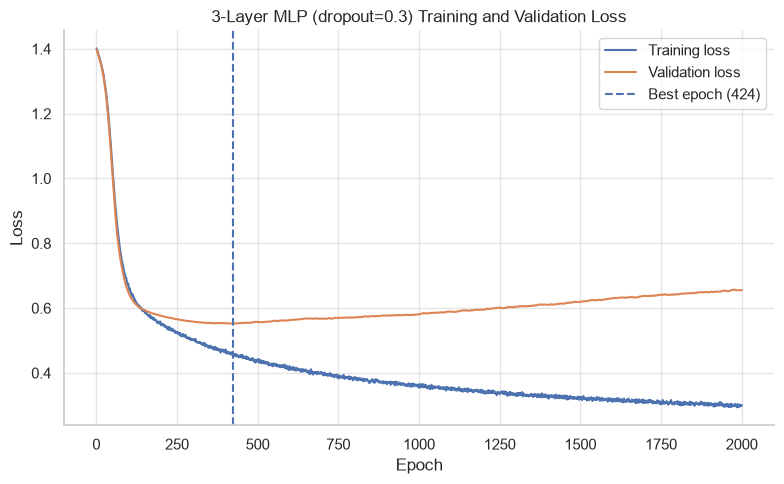

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.3) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_030_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (dropout=0.3)

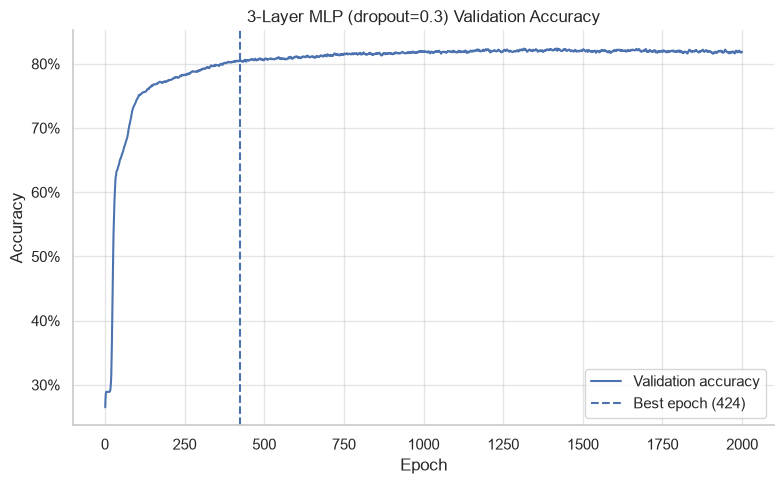

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.3) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_030_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (dropout=0.3) Candidate Results

In [16]:
# save 3-Layer MLP (dropout=0.3) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "dropout",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_03,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_dropout_030.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_dropout_030.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (dropout=0.55) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (dropout=0.55)

In [7]:
# optimiser
mlp3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 3-Layer MLP (dropout=0.55) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (dropout=0.55)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40260 | Val Loss: 1.39803 | Val Acc: 26.41%
Epoch [ 100/2000] Train Loss: 0.74986 | Val Loss: 0.68314 | Val Acc: 72.85%
Epoch [ 200/2000] Train Loss: 0.60511 | Val Loss: 0.58486 | Val Acc: 77.59%
Epoch [ 300/2000] Train Loss: 0.56373 | Val Loss: 0.56374 | Val Acc: 78.70%
Epoch [ 400/2000] Train Loss: 0.52940 | Val Loss: 0.55199 | Val Acc: 79.60%
Epoch [ 500/2000] Train Loss: 0.51440 | Val Loss: 0.54204 | Val Acc: 80.66%
Epoch [ 600/2000] Train Loss: 0.49745 | Val Loss: 0.53758 | Val Acc: 80.84%
Epoch [ 700/2000] Train Loss: 0.48372 | Val Loss: 0.53350 | Val Acc: 81.33%
Epoch [ 800/2000] Train Loss: 0.46920 | Val Loss: 0.53271 | Val Acc: 81.95%
Epoch [ 900/2000] Train Loss: 0.45585 | Val Loss: 0.53338 | Val Acc: 81.66%
Epoch [1000/2000] Train Loss: 0.44644 | Val Loss: 0.53419 | Val Acc: 81.93%
Epoch [1100/2000] Train Loss: 0.44411 | Val Loss: 0.53421 | Val Acc: 81.71%
Epoch [1200/2000] Train Loss: 0.43939 | Val Loss: 0.53585 | Val Acc: 81.8

Restore best result for 3-Layer MLP (dropout=0.55) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (dropout=0.55) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      725
Validation loss: 0.53161
Accuracy:        0.8153
Macro precision: 0.8052
Macro recall:    0.7949
Macro F1:        0.7991
Macro AUROC:     0.9499


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8337  R=0.8453  F1=0.8394  n=1299
Government       P=0.8287  R=0.8510  F1=0.8397  n=1376
Company          P=0.8128  R=0.8361  F1=0.8243  n=1153
Politician       P=0.7457  R=0.6471  F1=0.6929  n=666


Visualise Validation Loss for the 3-Layer MLP (dropout=0.55)

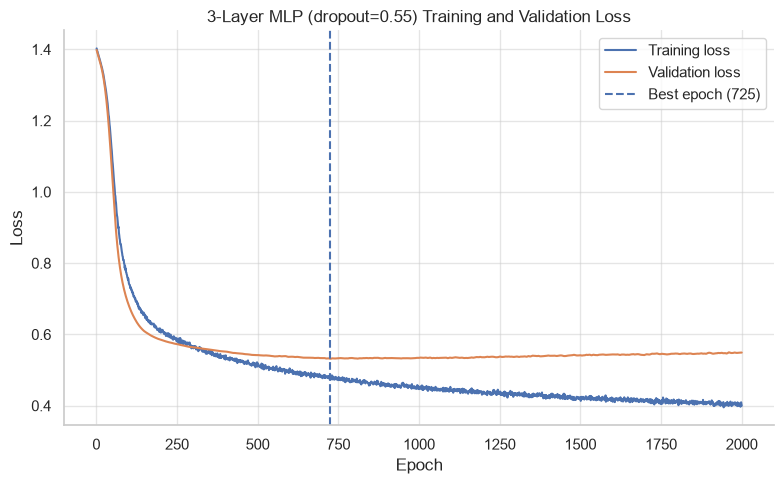

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.55) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_055_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (dropout=0.55)

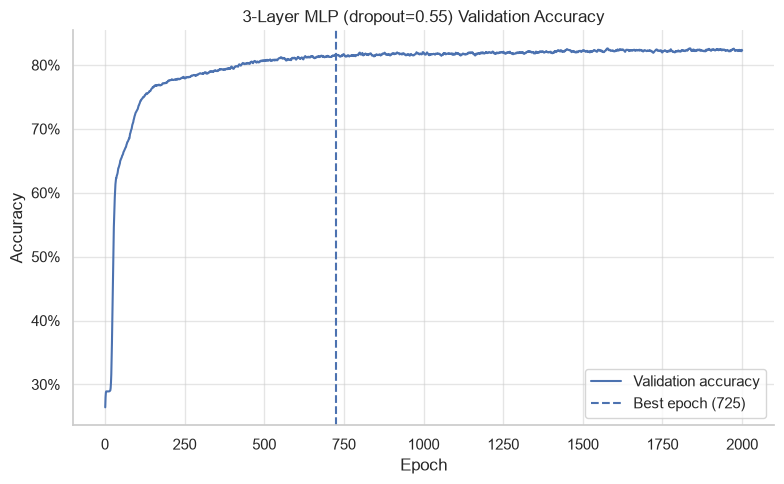

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.55) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_055_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (dropout=0.55) Candidate Results

In [16]:
# save 3-Layer MLP (dropout=0.55) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "dropout",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_dropout_055.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_dropout_055.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (dropout=0.6) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_06,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (dropout=0.6)

In [7]:
# optimiser
mlp3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 3-Layer MLP (dropout=0.6) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (dropout=0.6)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40297 | Val Loss: 1.39806 | Val Acc: 26.32%
Epoch [ 100/2000] Train Loss: 0.76860 | Val Loss: 0.69296 | Val Acc: 72.30%
Epoch [ 200/2000] Train Loss: 0.62221 | Val Loss: 0.58872 | Val Acc: 77.41%
Epoch [ 300/2000] Train Loss: 0.58444 | Val Loss: 0.56661 | Val Acc: 78.62%
Epoch [ 400/2000] Train Loss: 0.54746 | Val Loss: 0.55513 | Val Acc: 79.44%
Epoch [ 500/2000] Train Loss: 0.53083 | Val Loss: 0.54514 | Val Acc: 80.49%
Epoch [ 600/2000] Train Loss: 0.51701 | Val Loss: 0.53947 | Val Acc: 80.71%
Epoch [ 700/2000] Train Loss: 0.50521 | Val Loss: 0.53368 | Val Acc: 81.24%
Epoch [ 800/2000] Train Loss: 0.48800 | Val Loss: 0.53125 | Val Acc: 81.55%
Epoch [ 900/2000] Train Loss: 0.47687 | Val Loss: 0.53131 | Val Acc: 81.38%
Epoch [1000/2000] Train Loss: 0.46987 | Val Loss: 0.53257 | Val Acc: 81.49%
Epoch [1100/2000] Train Loss: 0.46809 | Val Loss: 0.53180 | Val Acc: 81.55%
Epoch [1200/2000] Train Loss: 0.46153 | Val Loss: 0.53101 | Val Acc: 81.8

Restore best result for 3-Layer MLP (dropout=0.6) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (dropout=0.6) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1050
Validation loss: 0.52999
Accuracy:        0.8169
Macro precision: 0.8071
Macro recall:    0.7952
Macro F1:        0.8000
Macro AUROC:     0.9509


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8313  R=0.8499  F1=0.8405  n=1299
Government       P=0.8273  R=0.8597  F1=0.8432  n=1376
Company          P=0.8208  R=0.8300  F1=0.8254  n=1153
Politician       P=0.7491  R=0.6411  F1=0.6909  n=666


Visualise Validation Loss for the 3-Layer MLP (dropout=0.6)

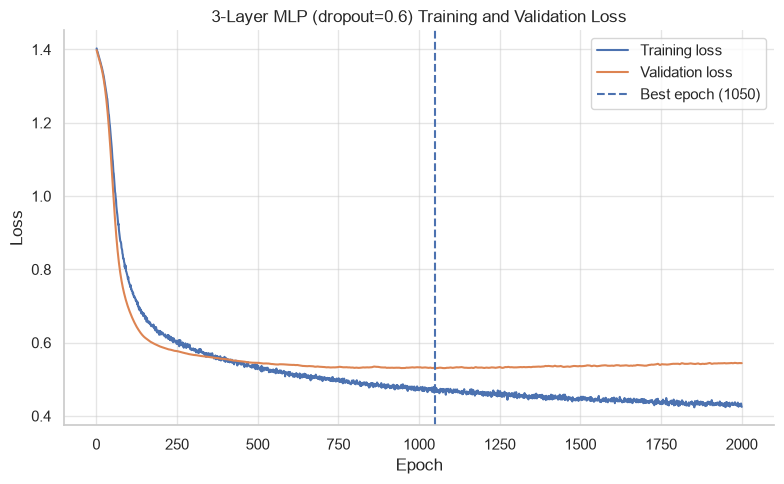

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.6) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_060_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (dropout=0.6)

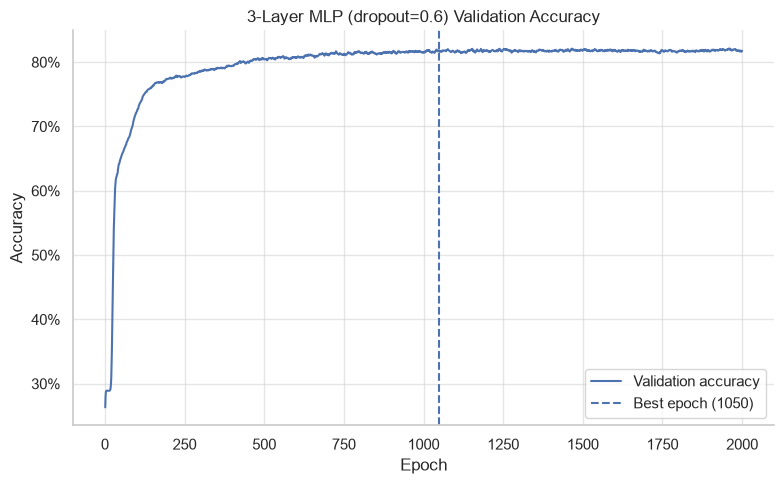

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.6) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_060_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (dropout=0.6) Candidate Results

In [16]:
# save 3-Layer MLP (dropout=0.6) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "dropout",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_06,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_dropout_060.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_dropout_060.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (dropout=0.7) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_07,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (dropout=0.7)

In [7]:
# optimiser
mlp3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 3-Layer MLP (dropout=0.7) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (dropout=0.7)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40419 | Val Loss: 1.39822 | Val Acc: 26.37%
Epoch [ 100/2000] Train Loss: 0.82480 | Val Loss: 0.71608 | Val Acc: 71.50%
Epoch [ 200/2000] Train Loss: 0.67295 | Val Loss: 0.60188 | Val Acc: 77.13%
Epoch [ 300/2000] Train Loss: 0.62505 | Val Loss: 0.57805 | Val Acc: 78.30%
Epoch [ 400/2000] Train Loss: 0.59637 | Val Loss: 0.56649 | Val Acc: 78.86%
Epoch [ 500/2000] Train Loss: 0.57874 | Val Loss: 0.55658 | Val Acc: 79.97%
Epoch [ 600/2000] Train Loss: 0.56630 | Val Loss: 0.55032 | Val Acc: 80.24%
Epoch [ 700/2000] Train Loss: 0.55522 | Val Loss: 0.54583 | Val Acc: 80.73%
Epoch [ 800/2000] Train Loss: 0.54364 | Val Loss: 0.54251 | Val Acc: 80.91%
Epoch [ 900/2000] Train Loss: 0.53162 | Val Loss: 0.54174 | Val Acc: 80.91%
Epoch [1000/2000] Train Loss: 0.52444 | Val Loss: 0.54069 | Val Acc: 81.24%
Epoch [1100/2000] Train Loss: 0.52873 | Val Loss: 0.54012 | Val Acc: 81.06%
Epoch [1200/2000] Train Loss: 0.51420 | Val Loss: 0.54003 | Val Acc: 81.2

Restore best result for 3-Layer MLP (dropout=0.7) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (dropout=0.7) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1237
Validation loss: 0.53782
Accuracy:        0.8129
Macro precision: 0.8042
Macro recall:    0.7888
Macro F1:        0.7946
Macro AUROC:     0.9507


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8202  R=0.8499  F1=0.8348  n=1299
Government       P=0.8225  R=0.8590  F1=0.8404  n=1376
Company          P=0.8199  R=0.8291  F1=0.8245  n=1153
Politician       P=0.7541  R=0.6171  F1=0.6788  n=666


Visualise Validation Loss for the 3-Layer MLP (dropout=0.7)

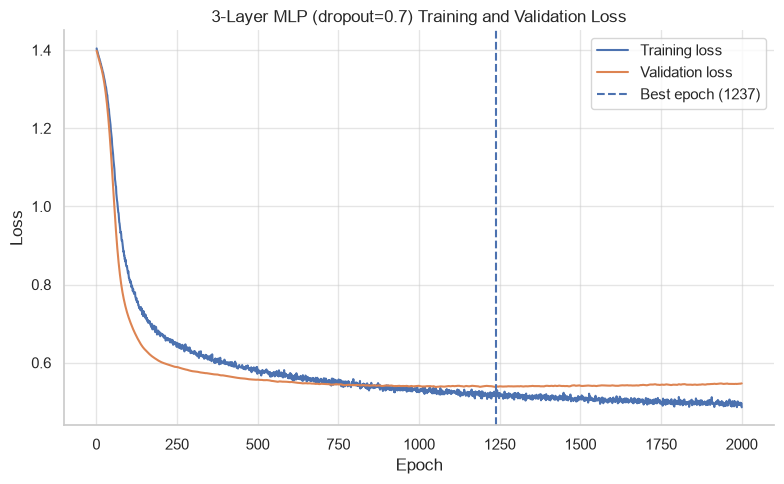

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.7) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_070_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (dropout=0.7)

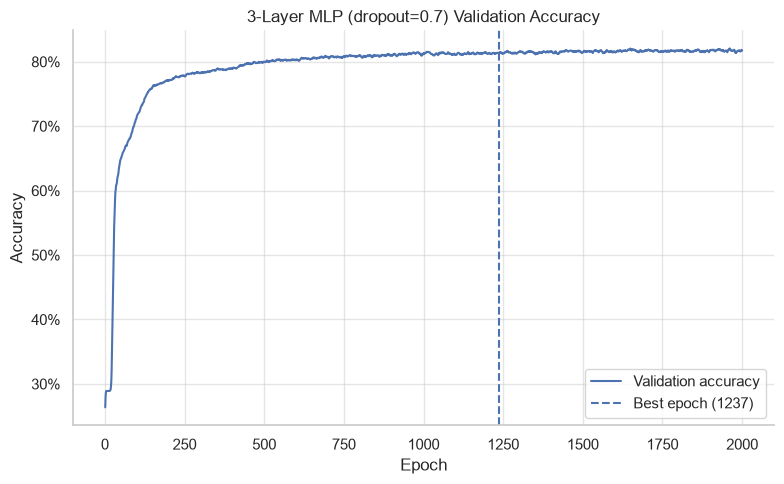

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (dropout=0.7) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_dropout_070_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (dropout=0.7) Candidate Results

In [16]:
# save 3-Layer MLP (dropout=0.7) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "dropout",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_07,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_dropout_070.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_dropout_070.pt",
)

Using a 3-Layer MLP, dropout values between 0.5 and 0.6 have similar validation performance.
Dropout 0.5 achieved the highest accuracy, macro-F1 and macro-AUROC.
Dropout 0.6 achieved the lowest validation loss.
Dropout 0.55 produced the highest Politician F1, but weaker aggregate metrics.
Dropout 0.5 showed strong per-class performance with majority wins and a Politician F1 that was<br>
near to the best F1.
Retain dropout 0.5 for subsequent tuning.

### Weight Decay Tuning

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (weight_decay=1e-4) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (weight_decay=1e-4)

In [7]:
# optimiser
mlp3_wd1e4_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_1E4,
)

#### Evaluate 3-Layer MLP (weight_decay=1e-4) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (weight_decay=1e-4)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_wd1e4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40239 | Val Loss: 1.39799 | Val Acc: 26.41%
Epoch [ 100/2000] Train Loss: 0.72885 | Val Loss: 0.67376 | Val Acc: 73.28%
Epoch [ 200/2000] Train Loss: 0.59093 | Val Loss: 0.58313 | Val Acc: 77.53%
Epoch [ 300/2000] Train Loss: 0.55150 | Val Loss: 0.56200 | Val Acc: 78.64%
Epoch [ 400/2000] Train Loss: 0.51705 | Val Loss: 0.55174 | Val Acc: 79.53%
Epoch [ 500/2000] Train Loss: 0.49830 | Val Loss: 0.54346 | Val Acc: 80.60%
Epoch [ 600/2000] Train Loss: 0.48329 | Val Loss: 0.53808 | Val Acc: 81.33%
Epoch [ 700/2000] Train Loss: 0.46752 | Val Loss: 0.53190 | Val Acc: 81.42%
Epoch [ 800/2000] Train Loss: 0.45676 | Val Loss: 0.52999 | Val Acc: 81.84%
Epoch [ 900/2000] Train Loss: 0.43777 | Val Loss: 0.52940 | Val Acc: 81.58%
Epoch [1000/2000] Train Loss: 0.43301 | Val Loss: 0.52906 | Val Acc: 82.00%
Epoch [1100/2000] Train Loss: 0.43148 | Val Loss: 0.52889 | Val Acc: 81.95%
Epoch [1200/2000] Train Loss: 0.41751 | Val Loss: 0.53040 | Val Acc: 82.2

Restore best result for 3-Layer MLP (weight_decay=1e-4) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (weight_decay=1e-4) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      922
Validation loss: 0.52815
Accuracy:        0.8175
Macro precision: 0.8082
Macro recall:    0.7967
Macro F1:        0.8013
Macro AUROC:     0.9510


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8324  R=0.8453  F1=0.8388  n=1299
Government       P=0.8292  R=0.8539  F1=0.8414  n=1376
Company          P=0.8180  R=0.8422  F1=0.8299  n=1153
Politician       P=0.7531  R=0.6456  F1=0.6952  n=666


Visualise Validation Loss for the 3-Layer MLP (weight_decay=1e-4)

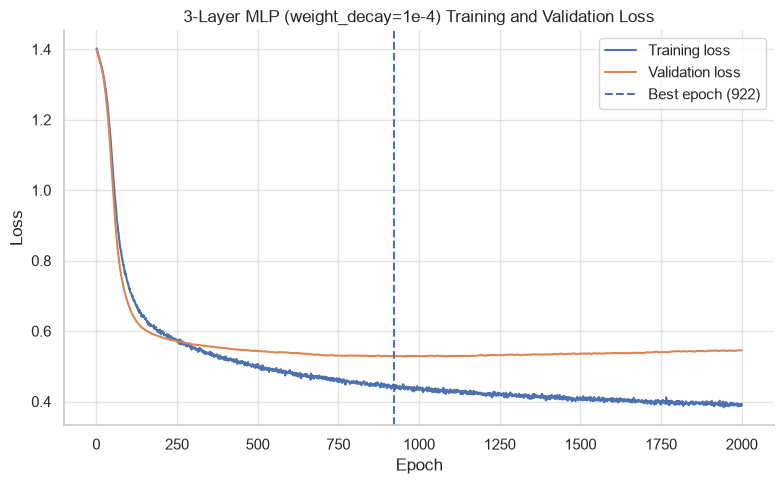

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=1e-4) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_wd1e4_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (weight_decay=1e-4)

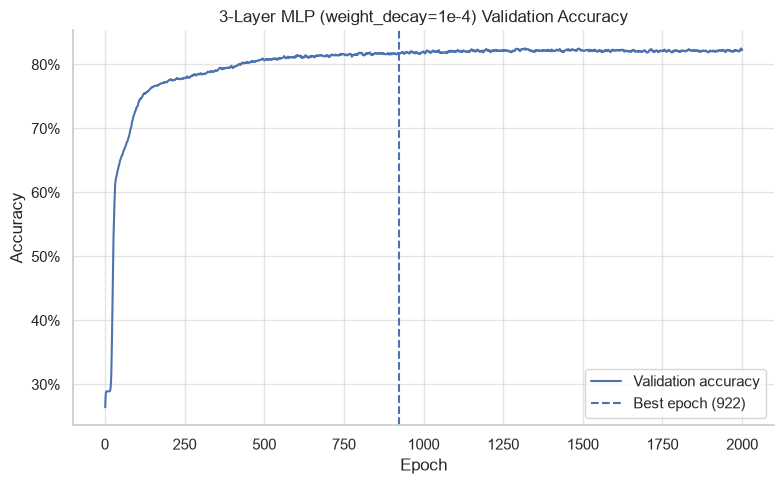

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=1e-4) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_wd1e4_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (weight_decay=1e-4) Candidate Results

In [16]:
# save 3-Layer MLP (weight_decay=1e-4) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "weight_decay",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_1E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_wd1e4.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_wd1e4.pt",
)

Reset the Torch seed rng

In [6]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (weight_decay=5e-4) network

In [7]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (weight_decay=5e-4)

In [8]:
# optimiser
mlp3_wd5e4_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (weight_decay=5e-4) Candidate

In [9]:
# perform training and validation of the 3-Layer MLP (weight_decay=5e-4)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_wd5e4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40239 | Val Loss: 1.39801 | Val Acc: 26.39%
Epoch [ 100/2000] Train Loss: 0.72771 | Val Loss: 0.67526 | Val Acc: 73.28%
Epoch [ 200/2000] Train Loss: 0.59339 | Val Loss: 0.58472 | Val Acc: 77.44%
Epoch [ 300/2000] Train Loss: 0.55804 | Val Loss: 0.56435 | Val Acc: 78.68%
Epoch [ 400/2000] Train Loss: 0.52681 | Val Loss: 0.55329 | Val Acc: 79.22%
Epoch [ 500/2000] Train Loss: 0.51303 | Val Loss: 0.54328 | Val Acc: 80.35%
Epoch [ 600/2000] Train Loss: 0.49856 | Val Loss: 0.53815 | Val Acc: 80.57%
Epoch [ 700/2000] Train Loss: 0.48670 | Val Loss: 0.53385 | Val Acc: 81.29%
Epoch [ 800/2000] Train Loss: 0.47518 | Val Loss: 0.53195 | Val Acc: 81.29%
Epoch [ 900/2000] Train Loss: 0.45934 | Val Loss: 0.53023 | Val Acc: 81.40%
Epoch [1000/2000] Train Loss: 0.45563 | Val Loss: 0.52861 | Val Acc: 81.51%
Epoch [1100/2000] Train Loss: 0.45652 | Val Loss: 0.52746 | Val Acc: 81.89%
Epoch [1200/2000] Train Loss: 0.44622 | Val Loss: 0.52691 | Val Acc: 81.9

Restore best result for 3-Layer MLP (weight_decay=5e-4) evaluation

In [10]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (weight_decay=5e-4) evaluation metrics


In [11]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1653
Validation loss: 0.52530
Accuracy:        0.8209
Macro precision: 0.8100
Macro recall:    0.7985
Macro F1:        0.8031
Macro AUROC:     0.9511


In [12]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8348  R=0.8522  F1=0.8434  n=1299
Government       P=0.8360  R=0.8597  F1=0.8477  n=1376
Company          P=0.8228  R=0.8456  F1=0.8340  n=1153
Politician       P=0.7465  R=0.6366  F1=0.6872  n=666


Visualise Validation Loss for the 3-Layer MLP (weight_decay=5e-4)

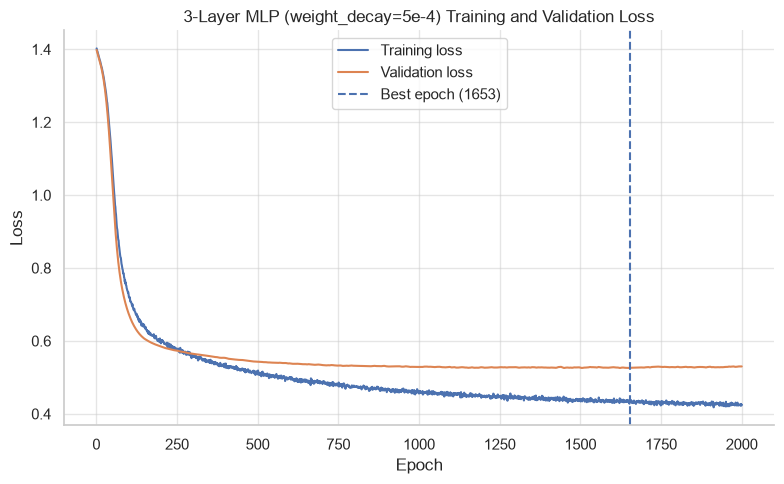

In [13]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=5e-4) Training and Validation Loss",
)

plt.show()

In [14]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_wd5e4_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (weight_decay=5e-4)

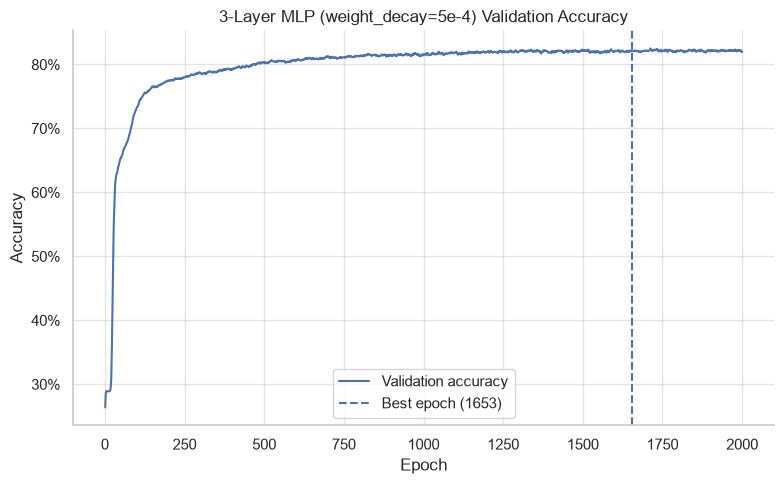

In [15]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=5e-4) Validation Accuracy",
)

plt.show()

In [16]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_wd5e4_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (weight_decay=5e-4) Candidate Results

In [17]:
# save 3-Layer MLP (weight_decay=5e-4) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "weight_decay",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_wd5e4.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_wd5e4.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (weight_decay=1e-3) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (weight_decay=1e-3)

In [7]:
# optimiser
mlp3_wd1e3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_1E3,
)

#### Evaluate 3-Layer MLP (weight_decay=1e-3) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (weight_decay=1e-3)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_wd1e3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40239 | Val Loss: 1.39807 | Val Acc: 26.44%
Epoch [ 100/2000] Train Loss: 0.72830 | Val Loss: 0.67763 | Val Acc: 73.03%
Epoch [ 200/2000] Train Loss: 0.59780 | Val Loss: 0.58732 | Val Acc: 77.21%
Epoch [ 300/2000] Train Loss: 0.56835 | Val Loss: 0.56759 | Val Acc: 78.44%
Epoch [ 400/2000] Train Loss: 0.53957 | Val Loss: 0.55723 | Val Acc: 79.02%
Epoch [ 500/2000] Train Loss: 0.52789 | Val Loss: 0.54956 | Val Acc: 79.62%
Epoch [ 600/2000] Train Loss: 0.51586 | Val Loss: 0.54460 | Val Acc: 79.82%
Epoch [ 700/2000] Train Loss: 0.50588 | Val Loss: 0.53965 | Val Acc: 80.55%
Epoch [ 800/2000] Train Loss: 0.49440 | Val Loss: 0.53738 | Val Acc: 80.69%
Epoch [ 900/2000] Train Loss: 0.48190 | Val Loss: 0.53463 | Val Acc: 80.86%
Epoch [1000/2000] Train Loss: 0.48053 | Val Loss: 0.53218 | Val Acc: 80.97%
Epoch [1100/2000] Train Loss: 0.48028 | Val Loss: 0.53095 | Val Acc: 81.15%
Epoch [1200/2000] Train Loss: 0.46933 | Val Loss: 0.52948 | Val Acc: 81.1

Restore best result for 3-Layer MLP (weight_decay=1e-3) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (weight_decay=1e-3) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1890
Validation loss: 0.52435
Accuracy:        0.8160
Macro precision: 0.8063
Macro recall:    0.7940
Macro F1:        0.7989
Macro AUROC:     0.9505


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8350  R=0.8453  F1=0.8401  n=1299
Government       P=0.8248  R=0.8619  F1=0.8429  n=1376
Company          P=0.8160  R=0.8309  F1=0.8234  n=1153
Politician       P=0.7496  R=0.6381  F1=0.6894  n=666


Visualise Validation Loss for the 3-Layer MLP (weight_decay=1e-3)

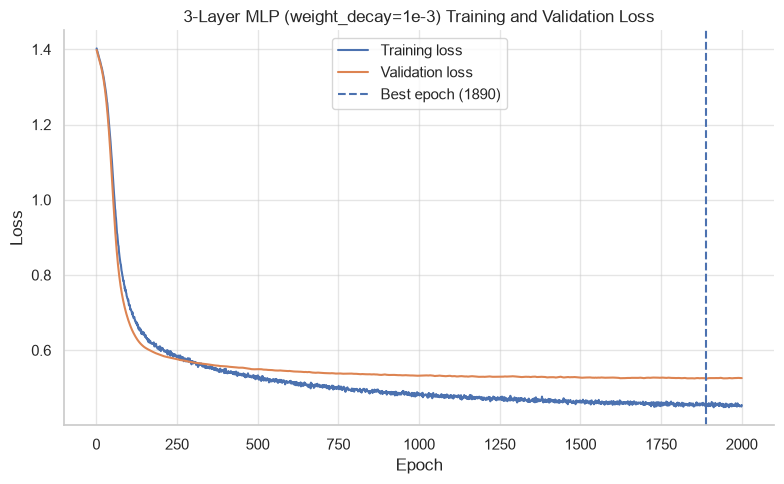

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=1e-3) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_wd1e3_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (weight_decay=1e-3)

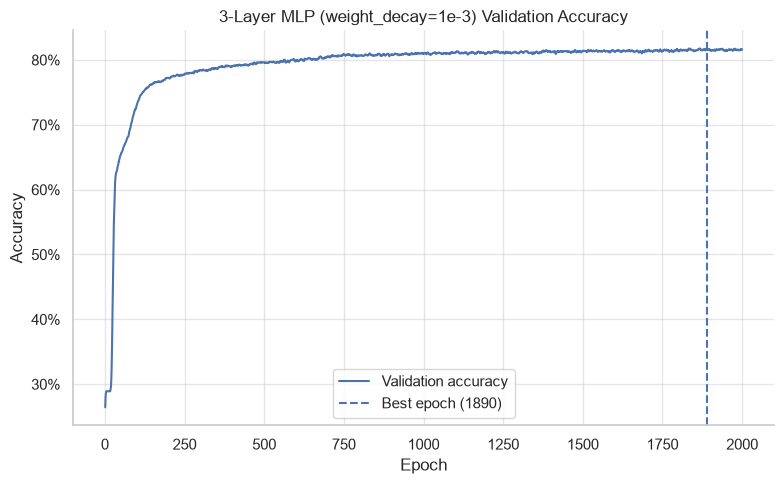

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=1e-3) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_wd1e3_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (weight_decay=1e-3) Candidate Results

In [16]:
# save 3-Layer MLP (weight_decay=1e-3) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "weight_decay",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_1E3,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_wd1e3.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_wd1e3.pt",
)

The optimum epoch for a weight decay of 1e-3 is close to the 2000e endpoint and so a 4000e run will be performed.

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (weight_decay=1e-3) network 4000e run

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (weight_decay=1e-3) 4000e run

In [7]:
# optimiser
mlp3_wd1e3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_1E3,
)

#### Evaluate 3-Layer MLP (weight_decay=1e-3) Candidate [4000e]

In [8]:
# perform training and validation of the 3-Layer MLP (weight_decay=1e-3)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_wd1e3_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training MLP
Epoch [   1/4000] Train Loss: 1.40239 | Val Loss: 1.39807 | Val Acc: 26.44%
Epoch [ 100/4000] Train Loss: 0.72830 | Val Loss: 0.67763 | Val Acc: 73.03%
Epoch [ 200/4000] Train Loss: 0.59780 | Val Loss: 0.58732 | Val Acc: 77.21%
Epoch [ 300/4000] Train Loss: 0.56835 | Val Loss: 0.56759 | Val Acc: 78.44%
Epoch [ 400/4000] Train Loss: 0.53957 | Val Loss: 0.55723 | Val Acc: 79.02%
Epoch [ 500/4000] Train Loss: 0.52789 | Val Loss: 0.54956 | Val Acc: 79.62%
Epoch [ 600/4000] Train Loss: 0.51586 | Val Loss: 0.54460 | Val Acc: 79.82%
Epoch [ 700/4000] Train Loss: 0.50588 | Val Loss: 0.53965 | Val Acc: 80.55%
Epoch [ 800/4000] Train Loss: 0.49440 | Val Loss: 0.53738 | Val Acc: 80.69%
Epoch [ 900/4000] Train Loss: 0.48190 | Val Loss: 0.53463 | Val Acc: 80.86%
Epoch [1000/4000] Train Loss: 0.48053 | Val Loss: 0.53218 | Val Acc: 80.97%
Epoch [1100/4000] Train Loss: 0.48028 | Val Loss: 0.53095 | Val Acc: 81.15%
Epoch [1200/4000] Train Loss: 0.46933 | Val Loss: 0.52948 | Val Acc: 81.1

Restore best result for 3-Layer MLP (weight_decay=1e-3) [4000e] evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (weight_decay=1e-3) [4000e] evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      2747
Validation loss: 0.52342
Accuracy:        0.8202
Macro precision: 0.8109
Macro recall:    0.7966
Macro F1:        0.8021
Macro AUROC:     0.9510


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8341  R=0.8476  F1=0.8408  n=1299
Government       P=0.8301  R=0.8699  F1=0.8495  n=1376
Company          P=0.8220  R=0.8413  F1=0.8315  n=1153
Politician       P=0.7572  R=0.6276  F1=0.6864  n=666


Visualise Validation Loss for the 3-Layer MLP (weight_decay=1e-3) [4000e]

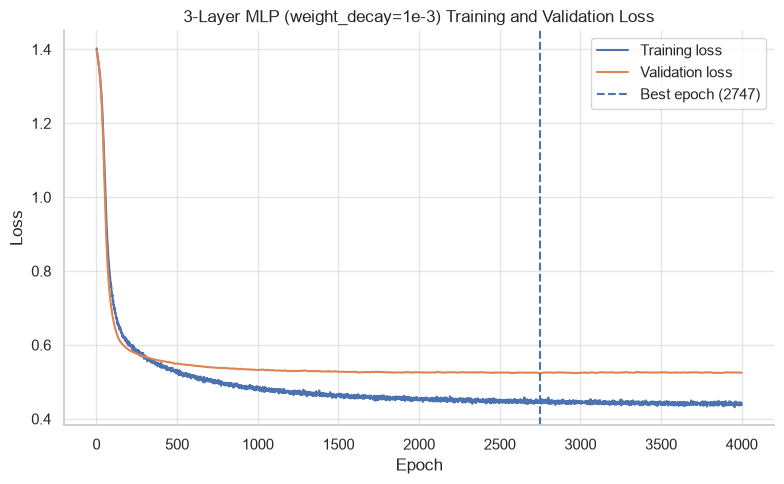

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=1e-3) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_wd1e3_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (weight_decay=1e-3) [4000e]

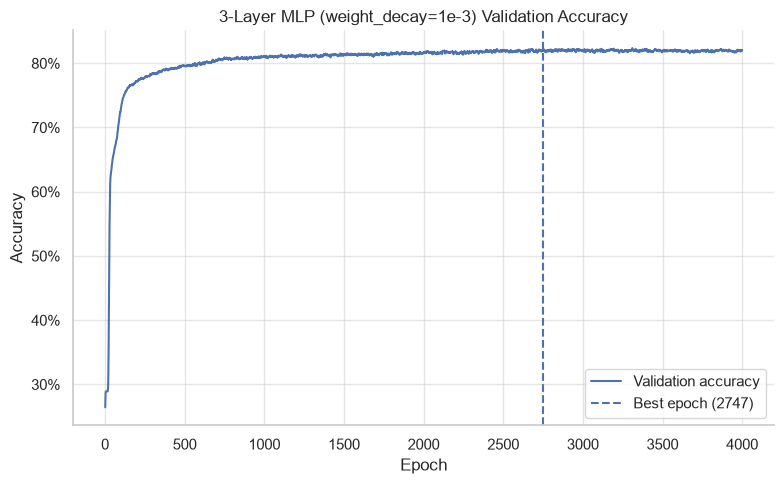

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=1e-3) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_wd1e3_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (weight_decay=1e-3) [4000e] Candidate Results

In [16]:
# save 3-Layer MLP (weight_decay=1e-3) [4000e] experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "weight_decay",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_1E3,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_wd1e3_4000e.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_wd1e3_4000e.pt",
)

The optimum epoch for a weight decay of 1e-3 was found to be 'late' (2747), and so a 4000e run will also be<br>
performed for a weight decay of 5e-4 (the current 'leading' value) to determine if it, too, has a late optimum.

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (weight_decay=5e-4) network 4000e run

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (weight_decay=5e-4) 4000e run

In [7]:
# optimiser
mlp3_wd5e4_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (weight_decay=5e-4) Candidate [4000e]

In [8]:
# perform training and validation of the 3-Layer MLP (weight_decay=5e-4)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_wd5e4_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training MLP
Epoch [   1/4000] Train Loss: 1.40239 | Val Loss: 1.39801 | Val Acc: 26.39%
Epoch [ 100/4000] Train Loss: 0.72771 | Val Loss: 0.67526 | Val Acc: 73.28%
Epoch [ 200/4000] Train Loss: 0.59339 | Val Loss: 0.58472 | Val Acc: 77.44%
Epoch [ 300/4000] Train Loss: 0.55804 | Val Loss: 0.56435 | Val Acc: 78.68%
Epoch [ 400/4000] Train Loss: 0.52681 | Val Loss: 0.55329 | Val Acc: 79.22%
Epoch [ 500/4000] Train Loss: 0.51303 | Val Loss: 0.54328 | Val Acc: 80.35%
Epoch [ 600/4000] Train Loss: 0.49856 | Val Loss: 0.53815 | Val Acc: 80.57%
Epoch [ 700/4000] Train Loss: 0.48670 | Val Loss: 0.53385 | Val Acc: 81.29%
Epoch [ 800/4000] Train Loss: 0.47518 | Val Loss: 0.53195 | Val Acc: 81.29%
Epoch [ 900/4000] Train Loss: 0.45934 | Val Loss: 0.53023 | Val Acc: 81.40%
Epoch [1000/4000] Train Loss: 0.45563 | Val Loss: 0.52861 | Val Acc: 81.51%
Epoch [1100/4000] Train Loss: 0.45652 | Val Loss: 0.52746 | Val Acc: 81.89%
Epoch [1200/4000] Train Loss: 0.44622 | Val Loss: 0.52691 | Val Acc: 81.9

Restore best result for 3-Layer MLP (weight_decay=5e-4) [4000e] evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (weight_decay=5e-4) [4000e] evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1653
Validation loss: 0.52530
Accuracy:        0.8209
Macro precision: 0.8100
Macro recall:    0.7985
Macro F1:        0.8031
Macro AUROC:     0.9511


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8348  R=0.8522  F1=0.8434  n=1299
Government       P=0.8360  R=0.8597  F1=0.8477  n=1376
Company          P=0.8228  R=0.8456  F1=0.8340  n=1153
Politician       P=0.7465  R=0.6366  F1=0.6872  n=666


Visualise Validation Loss for the 3-Layer MLP (weight_decay=5e-4) [4000e]

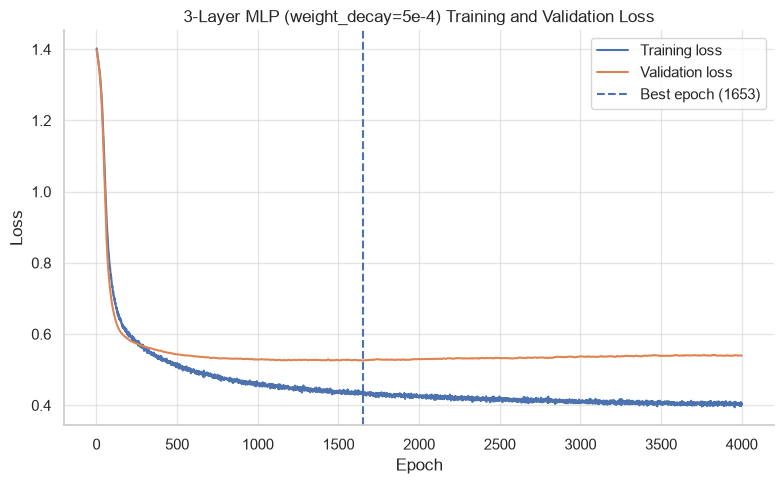

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=5e-4) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_wd5e4_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (5e-4) [4000e]

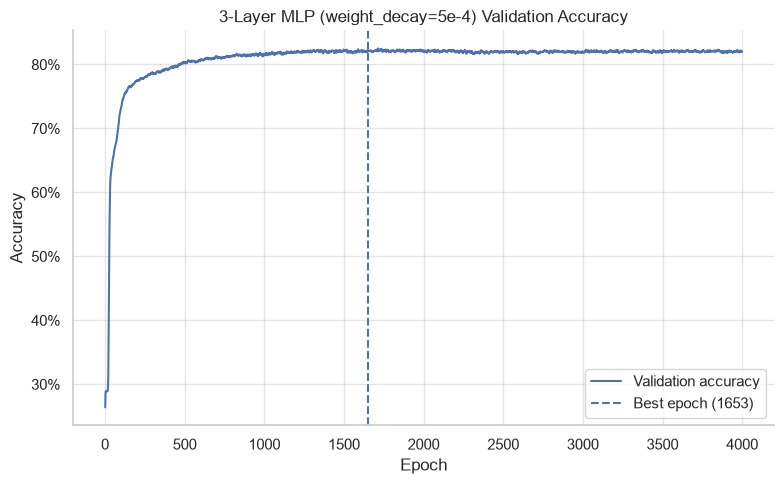

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=5e-4) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_wd5e4_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (weight_decay=5e-4) [4000e] Candidate Results

In [16]:
# save 3-Layer MLP (weight_decay=5e-4) [4000e] experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "weight_decay",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_wd5e4_4000e.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_wd5e4_4000e.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (weight_decay=5e-5) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (weight_decay=5e-5)

In [7]:
# optimiser
mlp3_wd5e5_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 3-Layer MLP (weight_decay=5e-5) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (weight_decay=5e-5)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_wd5e5_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40239 | Val Loss: 1.39798 | Val Acc: 26.39%
Epoch [ 100/2000] Train Loss: 0.72938 | Val Loss: 0.67388 | Val Acc: 73.30%
Epoch [ 200/2000] Train Loss: 0.59079 | Val Loss: 0.58286 | Val Acc: 77.44%
Epoch [ 300/2000] Train Loss: 0.55083 | Val Loss: 0.56187 | Val Acc: 78.64%
Epoch [ 400/2000] Train Loss: 0.51425 | Val Loss: 0.55164 | Val Acc: 79.75%
Epoch [ 500/2000] Train Loss: 0.49662 | Val Loss: 0.54295 | Val Acc: 80.75%
Epoch [ 600/2000] Train Loss: 0.48111 | Val Loss: 0.53866 | Val Acc: 81.00%
Epoch [ 700/2000] Train Loss: 0.46446 | Val Loss: 0.53467 | Val Acc: 81.58%
Epoch [ 800/2000] Train Loss: 0.45410 | Val Loss: 0.53385 | Val Acc: 82.00%
Epoch [ 900/2000] Train Loss: 0.43483 | Val Loss: 0.53490 | Val Acc: 81.71%
Epoch [1000/2000] Train Loss: 0.43028 | Val Loss: 0.53541 | Val Acc: 82.24%
Epoch [1100/2000] Train Loss: 0.42905 | Val Loss: 0.53575 | Val Acc: 81.78%
Epoch [1200/2000] Train Loss: 0.41614 | Val Loss: 0.53856 | Val Acc: 82.2

Restore best result for 3-Layer MLP (weight_decay=5e-5) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (weight_decay=5e-5) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      885
Validation loss: 0.53289
Accuracy:        0.8175
Macro precision: 0.8060
Macro recall:    0.7966
Macro F1:        0.8005
Macro AUROC:     0.9503


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8375  R=0.8453  F1=0.8414  n=1299
Government       P=0.8319  R=0.8561  F1=0.8438  n=1376
Company          P=0.8183  R=0.8395  F1=0.8288  n=1153
Politician       P=0.7363  R=0.6456  F1=0.6880  n=666


Visualise Validation Loss for the 3-Layer MLP (weight_decay=5e-5)

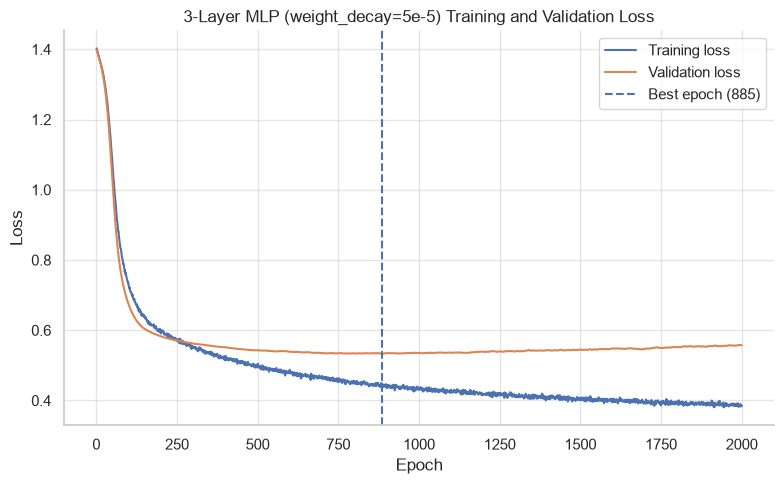

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=5e-5) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_wd5e5_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (weight_decay=5e-5)

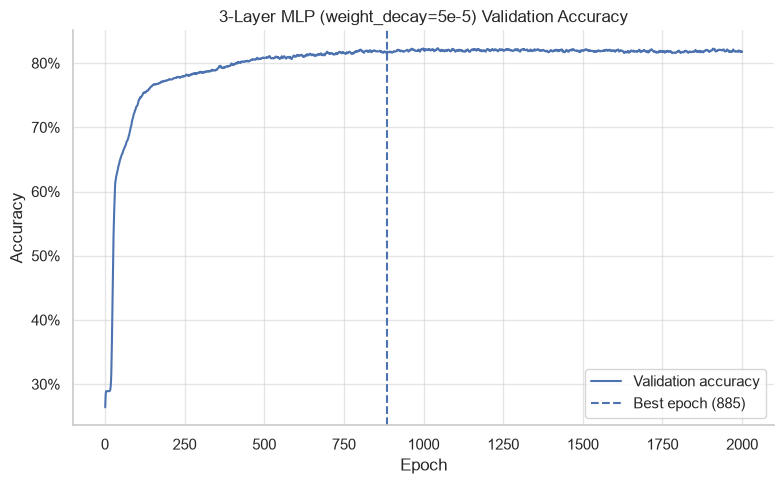

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (weight_decay=5e-5) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_wd5e5_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (weight_decay=5e-5) Candidate Results

In [16]:
# save 3-Layer MLP (weight_decay=5e-5) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "weight_decay",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_wd5e5.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_wd5e5.pt",
)

Weight decay of 5e-4 yields the strongest classification performance. The larger value of 1e-3 had<br>
slightly lower validation loss, but remained marginally weaker in accuracy and macro-F1.<br>
Weight decay 5e-5 had poorer performance than all of the larger weight-decay candidates.
Therefore, weight decay 5e-4 is retained for further tuning.

### Hidden Layers

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (hidden_channels=32) network

In [6]:
mlp3_hc32_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS_32,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (hidden_channels=32)

In [7]:
# optimiser
mlp3_hc32_optimizer = torch.optim.Adam(
    mlp3_hc32_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (hidden_channels=32) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (hidden_channels=32)

mlp3_result = train_mlp_model(
    model=mlp3_hc32_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_hc32_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.38469 | Val Loss: 1.38192 | Val Acc: 25.68%
Epoch [ 100/2000] Train Loss: 0.92778 | Val Loss: 0.83572 | Val Acc: 67.49%
Epoch [ 200/2000] Train Loss: 0.71787 | Val Loss: 0.64006 | Val Acc: 75.70%
Epoch [ 300/2000] Train Loss: 0.66318 | Val Loss: 0.60062 | Val Acc: 77.13%
Epoch [ 400/2000] Train Loss: 0.63453 | Val Loss: 0.58448 | Val Acc: 78.08%
Epoch [ 500/2000] Train Loss: 0.61799 | Val Loss: 0.57654 | Val Acc: 78.37%
Epoch [ 600/2000] Train Loss: 0.60028 | Val Loss: 0.56843 | Val Acc: 78.77%
Epoch [ 700/2000] Train Loss: 0.58341 | Val Loss: 0.56208 | Val Acc: 79.24%
Epoch [ 800/2000] Train Loss: 0.57392 | Val Loss: 0.55703 | Val Acc: 79.37%
Epoch [ 900/2000] Train Loss: 0.57307 | Val Loss: 0.55414 | Val Acc: 79.75%
Epoch [1000/2000] Train Loss: 0.56121 | Val Loss: 0.55023 | Val Acc: 79.97%
Epoch [1100/2000] Train Loss: 0.55756 | Val Loss: 0.54846 | Val Acc: 80.24%
Epoch [1200/2000] Train Loss: 0.54973 | Val Loss: 0.54591 | Val Acc: 80.2

Restore best result for 3-Layer MLP (hidden_channels=32) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_hc32_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_hc32_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_hc32_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (hidden_channels=32) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1923
Validation loss: 0.53499
Accuracy:        0.8138
Macro precision: 0.8061
Macro recall:    0.7894
Macro F1:        0.7955
Macro AUROC:     0.9492


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8320  R=0.8499  F1=0.8408  n=1299
Government       P=0.8167  R=0.8583  F1=0.8370  n=1376
Company          P=0.8127  R=0.8352  F1=0.8238  n=1153
Politician       P=0.7631  R=0.6141  F1=0.6805  n=666


Visualise Validation Loss for the 3-Layer MLP (hidden_channels=32)

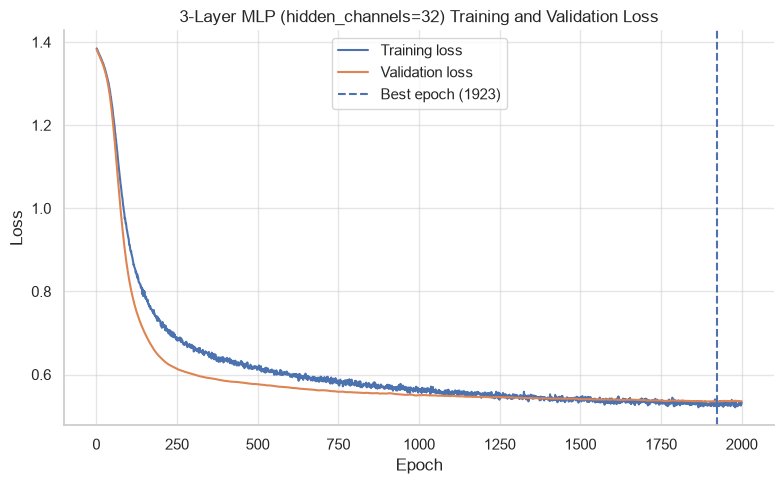

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (hidden_channels=32) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_hc32_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (hidden_channels=32)

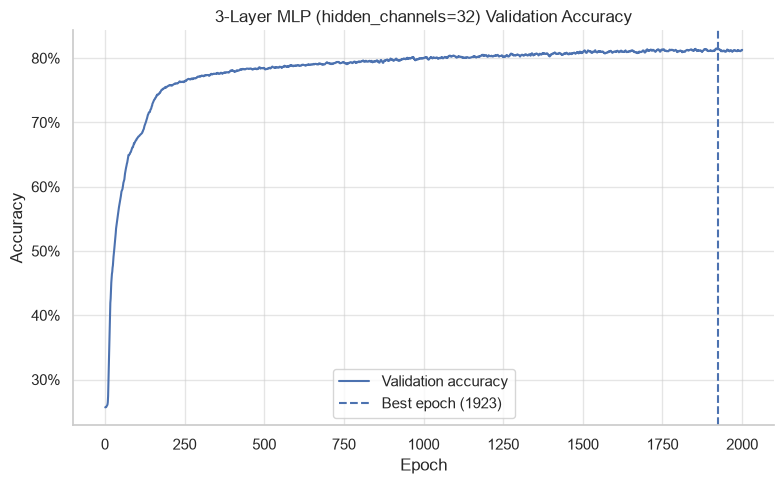

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (hidden_channels=32) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_hc32_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (hidden_channels=32) Candidate Results

In [16]:
# save 3-Layer MLP (hidden_channels=32) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "hidden_channels",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS_32,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_hc32.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_hc32.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (hidden_channels=128) network

In [6]:
mlp3_hc128_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS_128,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (hidden_channels=128)

In [7]:
# optimiser
mlp3_hc128_optimizer = torch.optim.Adam(
    mlp3_hc128_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (hidden_channels=128) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (hidden_channels=128)

mlp3_result = train_mlp_model(
    model=mlp3_hc128_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_hc128_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.38960 | Val Loss: 1.38388 | Val Acc: 26.23%
Epoch [ 100/2000] Train Loss: 0.59991 | Val Loss: 0.59615 | Val Acc: 76.06%
Epoch [ 200/2000] Train Loss: 0.51963 | Val Loss: 0.55972 | Val Acc: 78.26%
Epoch [ 300/2000] Train Loss: 0.46970 | Val Loss: 0.54579 | Val Acc: 79.51%
Epoch [ 400/2000] Train Loss: 0.44568 | Val Loss: 0.53985 | Val Acc: 80.46%
Epoch [ 500/2000] Train Loss: 0.42411 | Val Loss: 0.53757 | Val Acc: 80.93%
Epoch [ 600/2000] Train Loss: 0.40534 | Val Loss: 0.53849 | Val Acc: 81.42%
Epoch [ 700/2000] Train Loss: 0.39632 | Val Loss: 0.53682 | Val Acc: 81.82%
Epoch [ 800/2000] Train Loss: 0.38283 | Val Loss: 0.53918 | Val Acc: 81.42%
Epoch [ 900/2000] Train Loss: 0.37641 | Val Loss: 0.53859 | Val Acc: 81.69%
Epoch [1000/2000] Train Loss: 0.37203 | Val Loss: 0.54232 | Val Acc: 81.84%
Epoch [1100/2000] Train Loss: 0.36552 | Val Loss: 0.54447 | Val Acc: 81.73%
Epoch [1200/2000] Train Loss: 0.35819 | Val Loss: 0.54661 | Val Acc: 81.7

Restore best result for 3-Layer MLP (hidden_channels=128) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_hc128_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_hc128_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_hc128_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (hidden_channels=128) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      539
Validation loss: 0.53542
Accuracy:        0.8138
Macro precision: 0.8050
Macro recall:    0.7917
Macro F1:        0.7970
Macro AUROC:     0.9496


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8321  R=0.8430  F1=0.8375  n=1299
Government       P=0.8143  R=0.8634  F1=0.8381  n=1376
Company          P=0.8232  R=0.8239  F1=0.8236  n=1153
Politician       P=0.7504  R=0.6366  F1=0.6889  n=666


Visualise Validation Loss for the 3-Layer MLP (hidden_channels=128)

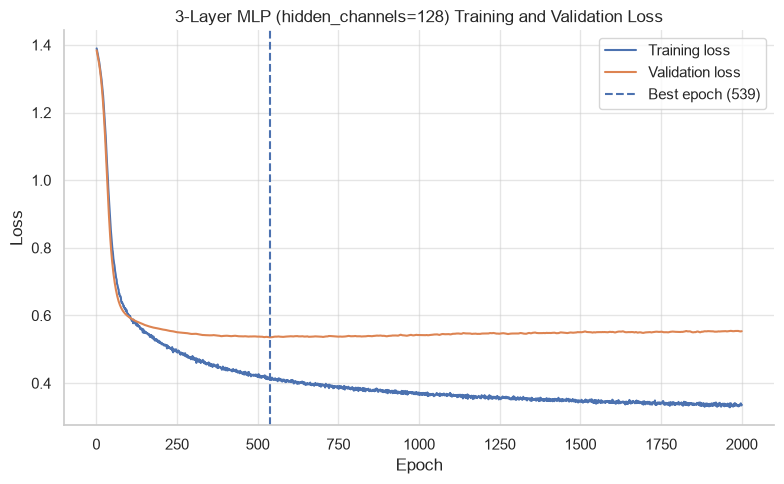

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (hidden_channels=128) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_hc128_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (hidden_channels=128)

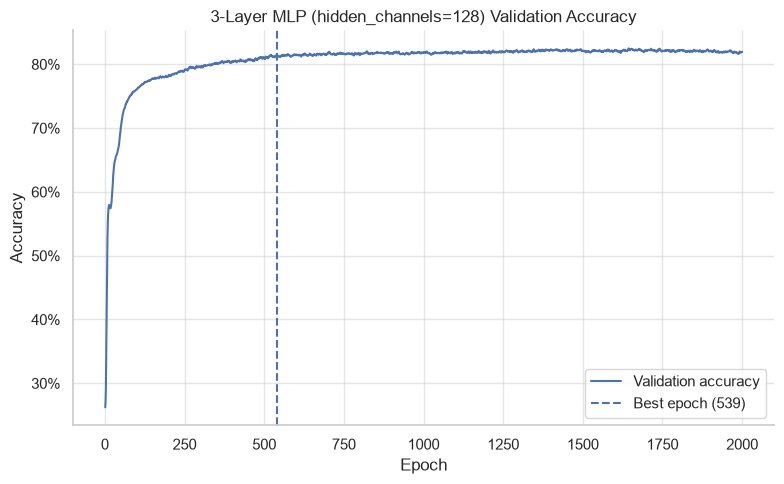

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (hidden_channels=128) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_hc128_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (hidden_channels=128) Candidate Results

In [16]:
# save 3-Layer MLP (hidden_channels=128) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "hidden_channels",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS_128,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_hc128.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_hc128.pt",
)

The hidden width of 32 reached its optimum at 1923/2000, near the 2000e boundary, but is already some way<br>
behind hidden width 64 across the aggregate metrics, and so will not be given an extended 4000e run.<br>
Hidden width 64 gave the strongest overall validation performance, achieving lowest validation loss and<br>
the highest accuracy, macro-F1, and macro-AUROC.<br>
Width 128 showed reduced aggregate performance, but did produce a marginally higher Politician F1.<br>
However, this difference is small.<br>
Hidden width 64 is retained for further tuning.

### Learning Rate

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (learning_rate=5e-4) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (learning_rate=5e-4)

In [7]:
# optimiser
mlp3_lr5e4_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE_5E4,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (learning_rate=5e-4) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (learning_rate=5e-4)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_lr5e4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40239 | Val Loss: 1.39964 | Val Acc: 24.94%
Epoch [ 100/2000] Train Loss: 0.98188 | Val Loss: 0.92929 | Val Acc: 66.56%
Epoch [ 200/2000] Train Loss: 0.69561 | Val Loss: 0.65263 | Val Acc: 74.39%
Epoch [ 300/2000] Train Loss: 0.62825 | Val Loss: 0.60092 | Val Acc: 76.41%
Epoch [ 400/2000] Train Loss: 0.59169 | Val Loss: 0.58272 | Val Acc: 77.46%
Epoch [ 500/2000] Train Loss: 0.57423 | Val Loss: 0.57137 | Val Acc: 78.06%
Epoch [ 600/2000] Train Loss: 0.55929 | Val Loss: 0.56308 | Val Acc: 78.73%
Epoch [ 700/2000] Train Loss: 0.54461 | Val Loss: 0.55706 | Val Acc: 79.04%
Epoch [ 800/2000] Train Loss: 0.53039 | Val Loss: 0.55207 | Val Acc: 79.60%
Epoch [ 900/2000] Train Loss: 0.51114 | Val Loss: 0.54766 | Val Acc: 79.95%
Epoch [1000/2000] Train Loss: 0.50688 | Val Loss: 0.54425 | Val Acc: 80.40%
Epoch [1100/2000] Train Loss: 0.50429 | Val Loss: 0.54122 | Val Acc: 80.42%
Epoch [1200/2000] Train Loss: 0.49252 | Val Loss: 0.53788 | Val Acc: 80.7

Restore best result for 3-Layer MLP (learning_rate=5e-4) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (learning_rate=5e-4) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1948
Validation loss: 0.52780
Accuracy:        0.8146
Macro precision: 0.8050
Macro recall:    0.7929
Macro F1:        0.7978
Macro AUROC:     0.9501


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8321  R=0.8468  F1=0.8394  n=1299
Government       P=0.8212  R=0.8576  F1=0.8390  n=1376
Company          P=0.8199  R=0.8291  F1=0.8245  n=1153
Politician       P=0.7469  R=0.6381  F1=0.6883  n=666


Visualise Validation Loss for the 3-Layer MLP (learning_rate=5e-4)

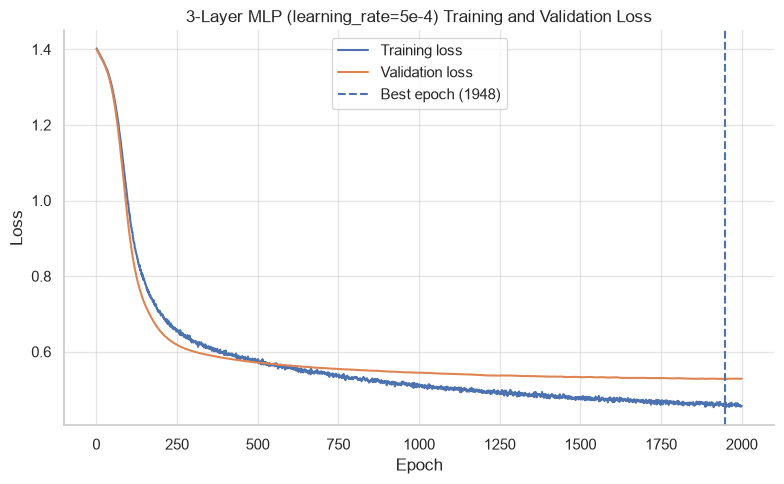

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (learning_rate=5e-4) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_lr5e4_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (learning_rate=5e-4)

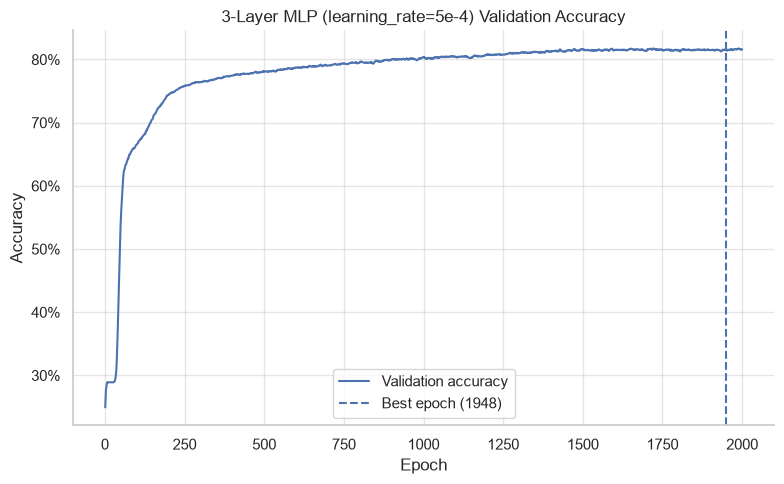

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (learning_rate=5e-4) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_lr5e4_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (learning_rate=5e-4) Candidate Results

In [16]:
# save 3-Layer MLP (learning_rate=5e-4) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "learning_rate",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE_5E4,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_lr5e4.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_lr5e4.pt",
)

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (learning_rate=2e-3) network

In [6]:
mlp3_model = MLPNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (learning_rate=2e-3)

In [7]:
# optimiser
mlp3_lr2e3_optimizer = torch.optim.Adam(
    mlp3_model.parameters(),
    lr=LEARNING_RATE_2E3,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (learning_rate=2e-3) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (learning_rate=2e-3)

mlp3_result = train_mlp_model(
    model=mlp3_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_lr2e3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40239 | Val Loss: 1.39479 | Val Acc: 27.99%
Epoch [ 100/2000] Train Loss: 0.61229 | Val Loss: 0.58915 | Val Acc: 77.35%
Epoch [ 200/2000] Train Loss: 0.52972 | Val Loss: 0.55435 | Val Acc: 79.28%
Epoch [ 300/2000] Train Loss: 0.49882 | Val Loss: 0.54102 | Val Acc: 80.51%
Epoch [ 400/2000] Train Loss: 0.46852 | Val Loss: 0.53314 | Val Acc: 81.02%
Epoch [ 500/2000] Train Loss: 0.46198 | Val Loss: 0.53127 | Val Acc: 81.38%
Epoch [ 600/2000] Train Loss: 0.45427 | Val Loss: 0.53131 | Val Acc: 81.42%
Epoch [ 700/2000] Train Loss: 0.44520 | Val Loss: 0.52798 | Val Acc: 81.55%
Epoch [ 800/2000] Train Loss: 0.43581 | Val Loss: 0.52877 | Val Acc: 81.89%
Epoch [ 900/2000] Train Loss: 0.42318 | Val Loss: 0.53099 | Val Acc: 82.00%
Epoch [1000/2000] Train Loss: 0.41890 | Val Loss: 0.52983 | Val Acc: 82.22%
Epoch [1100/2000] Train Loss: 0.42420 | Val Loss: 0.53159 | Val Acc: 82.33%
Epoch [1200/2000] Train Loss: 0.41532 | Val Loss: 0.53196 | Val Acc: 82.7

Restore best result for 3-Layer MLP (learning_rate=2e-3) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (learning_rate=2e-3) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      746
Validation loss: 0.52625
Accuracy:        0.8189
Macro precision: 0.8100
Macro recall:    0.7970
Macro F1:        0.8022
Macro AUROC:     0.9508


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8362  R=0.8491  F1=0.8426  n=1299
Government       P=0.8226  R=0.8663  F1=0.8439  n=1376
Company          P=0.8250  R=0.8300  F1=0.8275  n=1153
Politician       P=0.7562  R=0.6426  F1=0.6948  n=666


Visualise Validation Loss for the 3-Layer MLP (learning_rate=2e-3)

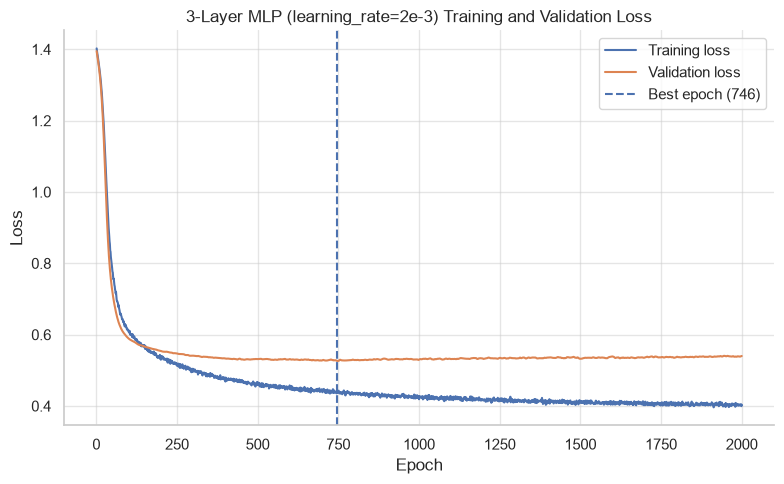

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (learning_rate=2e-3) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_lr2e3_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (learning_rate=2e-3)

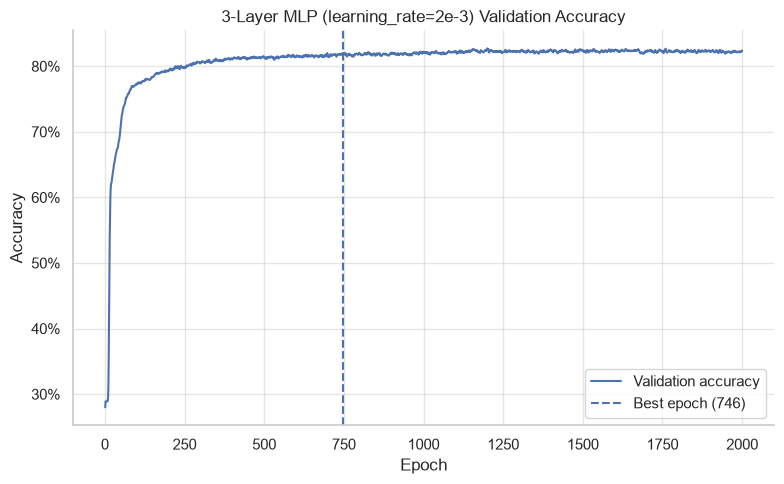

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (learning_rate=2e-3) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_lr2e3_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (learning_rate=2e-3) Candidate Results

In [16]:
# save 3-Layer MLP (learning_rate=2e-3) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "learning_rate",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE_2E3,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_lr2e3.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_lr2e3.pt",
)

The best epoch for 5e-4 occurred at 1948/2000, but its performance relative to 2e-3 and the default 1e-3<br>
does not justify a longer, 4000e run.
The default learning rate (1e-3) produced the strongest overall validation performance, having the<br>
lowest validation loss and highest accuracy, macro-F1, and macro-AUROC.<br>
The increased rate of 2e-3 produced similar aggregate performance, and an improved Politician F1,<br>
but had slightly reduced performance across the other classes.
The default learning rate (1e-3) will be retained for further tuning.

### Activation Function

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (activation: ELU) network

In [6]:
mlp3_elu_model = MLPNetwork3LayerELU(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (activation: ELU)

In [7]:
# optimiser
mlp3_elu_optimizer = torch.optim.Adam(
    mlp3_elu_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (activation: ELU) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (activation: ELU)

mlp3_result = train_mlp_model(
    model=mlp3_elu_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_elu_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40547 | Val Loss: 1.39441 | Val Acc: 24.52%
Epoch [ 100/2000] Train Loss: 0.66248 | Val Loss: 0.64130 | Val Acc: 73.83%
Epoch [ 200/2000] Train Loss: 0.59776 | Val Loss: 0.59810 | Val Acc: 75.77%
Epoch [ 300/2000] Train Loss: 0.59029 | Val Loss: 0.59360 | Val Acc: 76.28%
Epoch [ 400/2000] Train Loss: 0.58492 | Val Loss: 0.59224 | Val Acc: 76.55%
Epoch [ 500/2000] Train Loss: 0.58017 | Val Loss: 0.59099 | Val Acc: 76.84%
Epoch [ 600/2000] Train Loss: 0.57725 | Val Loss: 0.58971 | Val Acc: 77.01%
Epoch [ 700/2000] Train Loss: 0.57232 | Val Loss: 0.58800 | Val Acc: 77.01%
Epoch [ 800/2000] Train Loss: 0.57446 | Val Loss: 0.58675 | Val Acc: 77.04%
Epoch [ 900/2000] Train Loss: 0.57165 | Val Loss: 0.58483 | Val Acc: 77.21%
Epoch [1000/2000] Train Loss: 0.56779 | Val Loss: 0.58349 | Val Acc: 77.26%
Epoch [1100/2000] Train Loss: 0.56795 | Val Loss: 0.58280 | Val Acc: 77.24%
Epoch [1200/2000] Train Loss: 0.56551 | Val Loss: 0.58216 | Val Acc: 77.2

Restore best result for 3-Layer MLP (activation: ELU) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_elu_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_elu_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_elu_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (activation: ELU) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1999
Validation loss: 0.57619
Accuracy:        0.7786
Macro precision: 0.7746
Macro recall:    0.7522
Macro F1:        0.7599
Macro AUROC:     0.9407


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8109  R=0.8222  F1=0.8165  n=1299
Government       P=0.7535  R=0.8488  F1=0.7984  n=1376
Company          P=0.7923  R=0.7641  F1=0.7779  n=1153
Politician       P=0.7417  R=0.5736  F1=0.6469  n=666


Visualise Validation Loss for the 3-Layer MLP (activation: ELU)

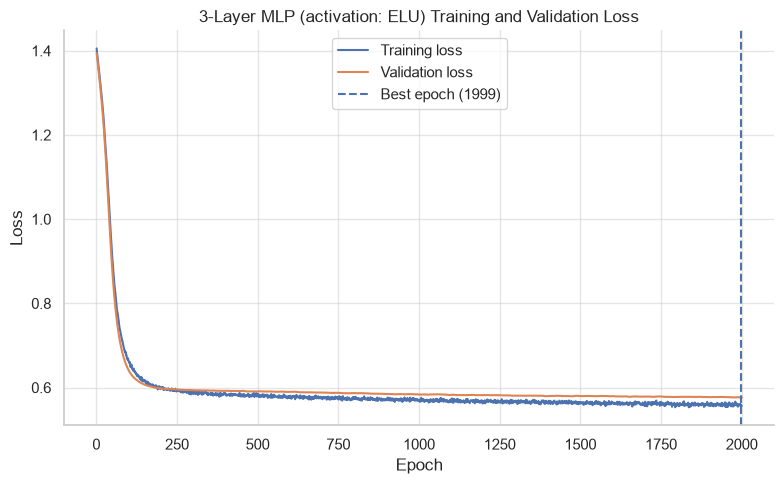

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (activation: ELU) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_elu_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (activation: ELU)

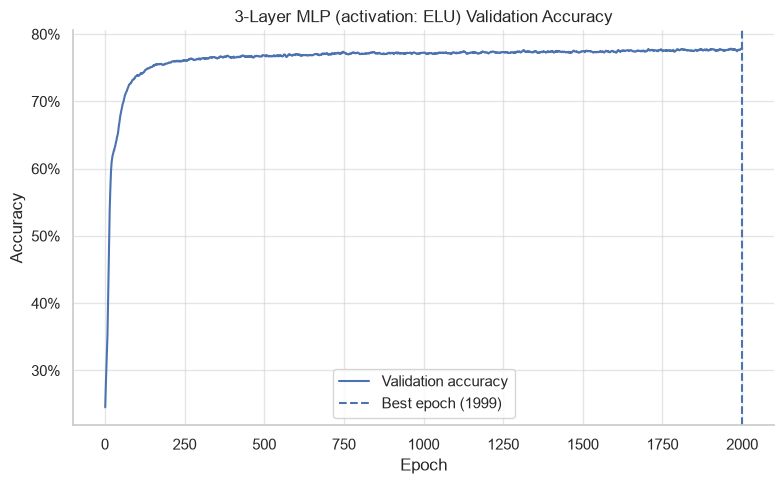

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (activation: ELU) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_elu_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (activation: ELU) Candidate Results

In [16]:
# save 3-Layer MLP (activation: ELU) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "activation",
    "activation": "ELU",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_elu.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_elu.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer MLP (activation: L-ReLU) network

In [6]:
mlp3_lrelu_model = MLPNetwork3LayerLReLU(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer MLP (activation: L-ReLU)

In [7]:
# optimiser
mlp3_lrelu_optimizer = torch.optim.Adam(
    mlp3_lrelu_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 3-Layer MLP (activation: L-ReLU) Candidate

In [8]:
# perform training and validation of the 3-Layer MLP (activation: L-ReLU)

mlp3_result = train_mlp_model(
    model=mlp3_lrelu_model,
    features=data.x,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=mlp3_lrelu_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training MLP
Epoch [   1/2000] Train Loss: 1.40240 | Val Loss: 1.39799 | Val Acc: 26.44%
Epoch [ 100/2000] Train Loss: 0.72546 | Val Loss: 0.67309 | Val Acc: 73.39%
Epoch [ 200/2000] Train Loss: 0.59259 | Val Loss: 0.58495 | Val Acc: 77.53%
Epoch [ 300/2000] Train Loss: 0.55880 | Val Loss: 0.56491 | Val Acc: 78.75%
Epoch [ 400/2000] Train Loss: 0.52613 | Val Loss: 0.55431 | Val Acc: 79.46%
Epoch [ 500/2000] Train Loss: 0.51318 | Val Loss: 0.54564 | Val Acc: 80.13%
Epoch [ 600/2000] Train Loss: 0.49969 | Val Loss: 0.54010 | Val Acc: 80.55%
Epoch [ 700/2000] Train Loss: 0.48667 | Val Loss: 0.53648 | Val Acc: 81.20%
Epoch [ 800/2000] Train Loss: 0.47576 | Val Loss: 0.53421 | Val Acc: 81.26%
Epoch [ 900/2000] Train Loss: 0.46117 | Val Loss: 0.53338 | Val Acc: 81.24%
Epoch [1000/2000] Train Loss: 0.45724 | Val Loss: 0.53214 | Val Acc: 81.53%
Epoch [1100/2000] Train Loss: 0.45758 | Val Loss: 0.53137 | Val Acc: 81.55%
Epoch [1200/2000] Train Loss: 0.44814 | Val Loss: 0.53098 | Val Acc: 81.8

Restore best result for 3-Layer MLP (activation: L-ReLU) evaluation

In [9]:
# check that a best state exists
if mlp3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
mlp3_lrelu_model.load_state_dict(
    mlp3_result["best_state"]
)

mlp3_lrelu_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    mlp3_logits = mlp3_lrelu_model(
        data.x,
    )

# calculate validation metrics
mlp3_metrics = classification_metrics(
    logits=mlp3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer MLP (activation: L-ReLU) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {mlp3_result['best_epoch']}\n"
    f"Validation loss: {mlp3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {mlp3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {mlp3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {mlp3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {mlp3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {mlp3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1449
Validation loss: 0.52951
Accuracy:        0.8186
Macro precision: 0.8080
Macro recall:    0.7976
Macro F1:        0.8019
Macro AUROC:     0.9504


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={mlp3_metrics['precision'][i]:.4f}  "
        f"R={mlp3_metrics['recall'][i]:.4f}  "
        f"F1={mlp3_metrics['f1'][i]:.4f}  "
        f"n={mlp3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.8351  R=0.8422  F1=0.8386  n=1299
Government       P=0.8308  R=0.8634  F1=0.8468  n=1376
Company          P=0.8228  R=0.8378  F1=0.8303  n=1153
Politician       P=0.7431  R=0.6471  F1=0.6918  n=666


Visualise Validation Loss for the 3-Layer MLP (activation: L-ReLU)

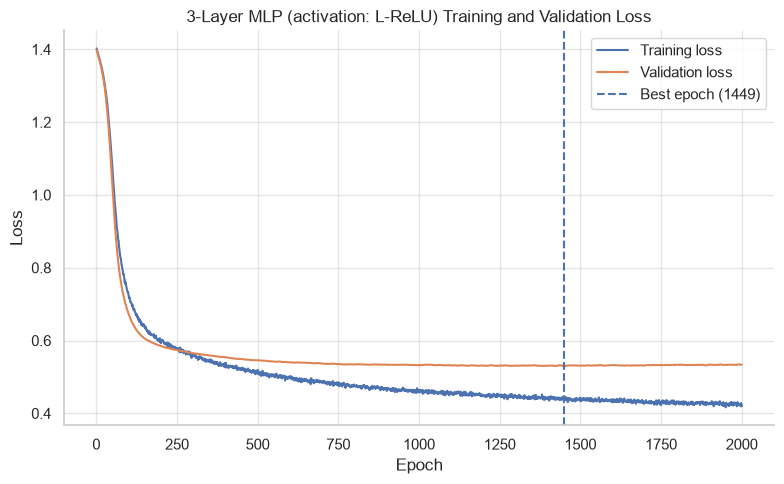

In [12]:
mlp3_loss_fig, _ = plot_training_validation_loss(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (activation: L-ReLU) Training and Validation Loss",
)

plt.show()

In [13]:
mlp3_loss_fig.savefig(
    FIGURES_DIR
    / "mlp_lrelu_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer MLP (activation: L-ReLU)

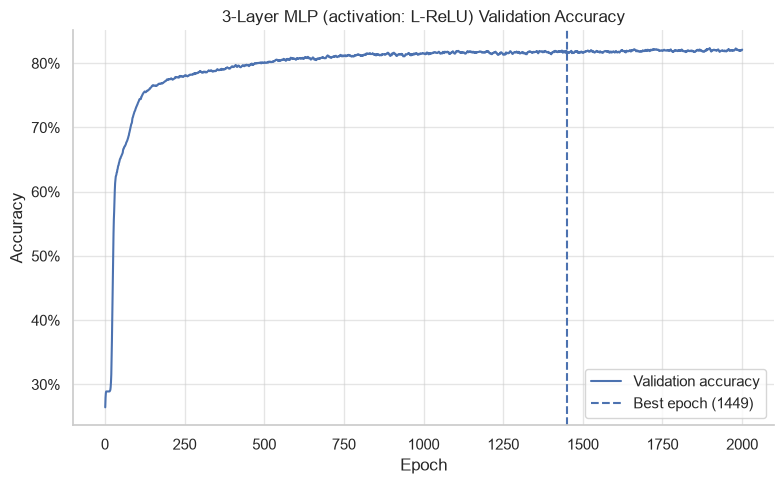

In [14]:
mlp3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=mlp3_result["history"],
    best_epoch=mlp3_result["best_epoch"],
    title="3-Layer MLP (activation: L-ReLU) Validation Accuracy",
)

plt.show()

In [15]:
mlp3_accuracy_fig.savefig(
    FIGURES_DIR
    / "mlp_lrelu_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer MLP (activation: L-ReLU) Candidate Results

In [16]:
# save 3-Layer MLP (activation: L-ReLU) experiment results
mlp3_results = {
    "model": "MLP",
    "experiment": "activation",
    "activation": "LeakyReLU",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": mlp3_result["best_epoch"],
    "best_val_loss": mlp3_result["best_val_loss"],
    "training_seconds": mlp3_result["elapsed"],
    "device": str(device),
    "validation_metrics": mlp3_metrics,
    "history": mlp3_result["history"],
}

with (
    RESULTS_DIR / "mlp_lrelu.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mlp3_results,
        file,
        indent=2,
    )

torch.save(
    mlp3_result["best_state"],
    CHECKPOINTS_DIR / "mlp_lrelu.pt",
)

LeakyReLU improved Politician F1 due to higher recall, but the original ReLU activation still wins<br>
every aggregate metric, the other three classes, and was relatively close on Politician F1.<br>
ELU had its best checkpoint at epoch 1999/2000, but is clearly worse than both ReLU and LeakyReLU, and so will<br>
not be given an extended 4000e run.<br>
Therefore, the original ReLU activation will be retained.

#### 'Frozen' MLP Model:

Selected Model: mlp_wd5e4.pt

3 layers, ReLU, Adam<br>
dropout = 0.5<br>
weight_decay = 5e-4<br>
64 hidden channels<br>
learning_rate = 1e-3<br>

checkpoint - minimum validation cross-entropy: epoch 1653